# Bike Trips Analysis

## Project Overview

This project analyzes a dataset of urban bike-sharing trips in Yerevan, Armenia.

The goal is to explore ride patterns, identify factors associated with trip duration and demand, evaluate user behavior, and investigate the relationship between weather conditions, bike types, and customer satisfaction.

The project also focuses on data quality, including missing values, duplicate records, inconsistent categories, and suspicious measurements.

## Objectives

- Clean and prepare the dataset for analysis.
- Perform exploratory data analysis (EDA).
- Create additional features to support the investigation.
- Test hypotheses about bike-sharing usage patterns.
- Visualize key findings using data visualization libraries.
- Develop data-driven recommendations to improve the bike-sharing service.

## Tools and Technologies

- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## Dataset

The dataset contains bike-sharing trip records from March to September 2026. It includes information about trip timestamps, stations, user types, bike types, weather conditions, trip duration, distance, pricing, and customer ratings.

The dataset contains intentionally introduced data quality issues, which will be investigated and addressed during the data preparation stage.

## Project Workflow

1. Data Loading and Initial Inspection
2. Data Cleaning and Preparation
3. Feature Engineering
4. Exploratory Data Analysis
5. Hypothesis Testing and Visualization
6. Key Findings and Business Recommendations

## Import Libraries

In [981]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



## Load Dataset and Preview Dataset

In [982]:
df = pd.read_csv("data/bike_trips_dirty - bike_trips_dirty.csv")

df.head()

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported
0,B203037,2026-09-06 12:56:00,University,Erebuni,subscriber,electric,app,sunny,18.3,36.1,5.11,855.0,5.0,no,33.0,yes
1,B206348,2026-08-26 15:29:00,Arabkir Park,Yerevan Mall,subscriber,standard,app,cloudy,NaN,16.0,2.68,455.0,NaN,no,31.0,no
2,B206561,2026-04-10 20:49:00,Victory Park,University,casual,standard,app,cloudy,17.1,27.4,NaN,671.0,5.0,no,19.0,no
3,B203971,2026-08-12 19:09:00,Republic Square,Komitas Market,subscriber,standard,app,cloudy,24.9,14.3,1.94,384.0,NaN,no,62.0,no
4,B200688,2026-07-14 20:49:00,YEREVAN MALL,Cascade,subscriber,electric,APP,cloudy,20.1,14.2,2.37,595.0,5.0,no,18.0,no


## Initial Data Inspection

In this section, we will examine the dataset's dimensions, column names, data types, and overall structure.

In [983]:
df.shape


(7340, 16)

In [984]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7340 entries, 0 to 7339
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   trip_id              7340 non-null   str    
 1   started_at           7340 non-null   str    
 2   start_station        7216 non-null   str    
 3   end_station          7340 non-null   str    
 4   user_type            7340 non-null   str    
 5   bike_type            7340 non-null   str    
 6   payment_method       7255 non-null   str    
 7   weather              7340 non-null   str    
 8   temperature_c        7231 non-null   str    
 9   duration_min         7340 non-null   float64
 10  distance_km          7155 non-null   float64
 11  price_amd            7340 non-null   str    
 12  rating               6182 non-null   float64
 13  technical_issue      7340 non-null   str    
 14  user_age             7159 non-null   float64
 15  is_weekend_reported  7340 non-null   str    
dtyp

##  Data Quality Inspection

The initial inspection revealed that some columns may have incorrect data types, such as dates and numeric values stored as strings.

We will examine each column individually to identify missing values, duplicates, inconsistent formatting, and suspicious entries. No changes will be made until the issues are investigated and appropriate cleaning rules are defined.

### Column: `trip_id`

Initially, the dataset contained 7,340 rows. We checked the column for missing values and found none.

We identified 140 repeated trip ID occurrences. After inspecting records with the same IDs, we confirmed that the examined records contained identical trip information. We removed fully duplicated rows using `drop_duplicates()`, reducing the dataset to 7,200 rows. This prevents identical records from being counted more than once during the analysis.

We also checked the format of the trip IDs. All IDs started with the uppercase letter `B`, and all characters in the identifiers were uppercase.

After cleaning, the column contained 7,200 unique trip IDs and no missing values. No additional changes to the ID format were necessary.    

In [985]:
# Inspect trip_id column

print("Missing values:", df["trip_id"].isna().sum())
print("Unique values:", df["trip_id"].nunique())
print("Unique trip IDs:", df["trip_id"].unique())

Missing values: 0
Unique values: 7200
Unique trip IDs: <StringArray>
['B203037', 'B206348', 'B206561', 'B203971', 'B200688', 'B204436', 'B203211',
 'B206671', 'B203289', 'B201058',
 ...
 'B202527', 'B202952', 'B204587', 'B206646', 'B205478', 'B200356', 'B207104',
 'B204908', 'B206276', 'B202933']
Length: 7200, dtype: str


In [986]:
# Count duplicated trip IDs
df["trip_id"].duplicated().sum()

np.int64(140)

In [987]:
# Inspect the first 5 duplicated trip IDs
df[df["trip_id"].duplicated(keep=False)].head()

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported
5,B204436,2026-05-17 8:37:00,Cascade,Erebuni,subscriber,standard,card,sunny,20.1,29.0,3.61,543.0,5.0,no,NaN,yes
37,B202311,2026-06-04 6:06:00,Cascade,Arabkir Park,casual,standard,card,CLOUDY,17.7,27.4,3.68,650.0,5.0,no,34.0,no
54,B203741,2026-08-24 12:40:00,Opera,Komitas Market,subscriber,standard,app,sunny,13.5,16.9,2.28,417.0,5.0,no,63.0,no
67,B202887,2026-06-25 22:21:00,University,University,subscriber,electric,card,rainy,24.3,7.9,1.37,500.0,5.0,no,51.0,no
81,B203594,2026-09-27 20:17:00,Erebuni,Erebuni,subscriber,standard,app,sunny,19.9,13.0,1.61,353.0,5.0,no,51.0,yes


In [988]:
# Test 1 Compare records with the same trip ID
df[df["trip_id"] == "B204436"]

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported
5,B204436,2026-05-17 8:37:00,Cascade,Erebuni,subscriber,standard,card,sunny,20.1,29.0,3.61,543.0,5.0,no,NaN,yes
3979,B204436,2026-05-17 8:37:00,Cascade,Erebuni,subscriber,standard,card,sunny,20.1,29.0,3.61,543.0,5.0,no,NaN,yes


In [989]:
# Test 2 Compare records with the same trip ID
df[df["trip_id"] == "B202311"]

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported
37,B202311,2026-06-04 6:06:00,Cascade,Arabkir Park,casual,standard,card,CLOUDY,17.7,27.4,3.68,650.0,5.0,no,34.0,no
4254,B202311,2026-06-04 6:06:00,Cascade,Arabkir Park,casual,standard,card,CLOUDY,17.7,27.4,3.68,650.0,5.0,no,34.0,no


### Duplicate Records

During the data quality inspection, we identified 140 duplicated records. After comparing records with the same `trip_id`, we confirmed that the inspected rows contained identical trip information.

These duplicates could distort the analysis by counting the same trips more than once. Therefore, we will remove fully duplicated rows while preserving the original dataset for reference.

In [990]:
# Remove fully duplicated rows
df = df.drop_duplicates()

In [991]:
# Check the number of remaining duplicate rows
df.duplicated().sum()

np.int64(0)

In [992]:
# Check trip IDs that do not start with 'B'
df[~df["trip_id"].str.startswith("B")]["trip_id"].unique()

<StringArray>
[]
Length: 0, dtype: str

In [993]:
# Check trip IDs for lowercase letters
df["trip_id"].str.isupper().all()

np.True_

### Column: `started_at`

We checked the column for missing values, inspected unique timestamps, and verified that all values followed the expected date and time format (`YYYY-MM-DD HH:MM:SS`).

Initially, the timestamps were stored as strings. We converted the column to the `datetime64[ns]` data type to support date-based analysis and time feature extraction.

The column contained no missing values or invalid timestamp formats. After cleaning, it contained 7,090 unique timestamps across 7,200 rows. Repeated timestamps were retained because multiple trips can start at the same time.

No rows were deleted, and no missing values were introduced.

In [994]:
# Inspect started_at column

print("Missing values:", df["started_at"].isna().sum())
print("Unique values:", df["started_at"].nunique())
print("Unique timestamps:", df["started_at"].unique())

Missing values: 0
Unique values: 7090
Unique timestamps: <StringArray>
['2026-09-06 12:56:00', '2026-08-26 15:29:00', '2026-04-10 20:49:00',
 '2026-08-12 19:09:00', '2026-07-14 20:49:00',  '2026-05-17 8:37:00',
 '2026-04-19 12:01:00', '2026-03-31 19:33:00', '2026-06-20 20:48:00',
  '2026-09-24 8:20:00',
 ...
 '2026-05-09 11:03:00', '2026-09-26 19:14:00', '2026-03-16 12:11:00',
 '2026-09-24 19:38:00', '2026-06-27 19:13:00', '2026-03-24 19:48:00',
 '2026-05-30 21:31:00',  '2026-08-04 8:55:00', '2026-05-29 10:27:00',
 '2026-06-04 23:48:00']
Length: 7090, dtype: str


In [995]:
# Check whether all timestamps match the expected format
pd.to_datetime(df["started_at"], format="%Y-%m-%d %H:%M:%S", errors="coerce").isna().sum()

np.int64(0)

In [996]:
# Convert start timestamps to datetime
df["started_at"] = pd.to_datetime(df["started_at"])

In [997]:
# Verify the data type
df["started_at"].dtype

dtype('<M8[us]')

### Column: `start_station`

We inspected the column for missing values and inconsistent station names. Initially, the column contained 118 missing values and four text placeholders recorded as `"Nan"`.

We standardized station names by removing leading and trailing whitespace and applying consistent capitalization using `str.strip().str.title()`. This resolved capitalization inconsistencies across station names.

The four text placeholders were then converted to proper missing values, resulting in 122 missing values in total. After standardization, the column contained 11 distinct non-missing station names.

No rows were deleted, and the remaining trip information was preserved. Missing station names were retained as `NaN` because the correct station could not be determined from the available data.

In [998]:
# Inspect start_station column
print("Missing values:", df["start_station"].isna().sum())
print("Unique values:", df["start_station"].nunique())
print("Unique station names:", df["start_station"].unique())

Missing values: 118
Unique values: 21
Unique station names: <StringArray>
[     'University',    'Arabkir Park',    'Victory Park', 'Republic Square',
    'YEREVAN MALL',         'Cascade',               nan,  'Komitas Market',
           'Opera',    'Yerevan Mall', 'REPUBLIC SQUARE',    'Barekamutyun',
         'Erebuni',  'KOMITAS MARKET',         'CASCADE',    'ARABKIR PARK',
         'EREBUNI',    'VICTORY PARK',      'UNIVERSITY',           'OPERA',
    'BAREKAMUTYUN',             'NAN']
Length: 22, dtype: str


In [999]:
# Inspect the first 5 rows with missing start stations
df[df["start_station"].isna()].head()

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported
10,B206423,2026-08-24 21:40:00,NaN,Opera,subscriber,electric,app,sunny,23.2,14.0,2.88,644.0,4.0,no,NaN,no
246,B201162,2026-04-22 22:15:00,NaN,Erebuni,casual,standard,cash,rainy,23.9,6.8,1.01,396.0,5.0,no,29.0,no
294,B201311,2026-05-11 16:08:00,NaN,Arabkir Park,casual,electric,card,cloudy,35.2,56.7,11.28,1542.0,3.0,no,65.0,no
386,B203050,2026-07-13 07:04:00,NaN,Erebuni,subscriber,electric,card,sunny,NaN,12.8,NaN,608.0,4.0,NO,64.0,no
418,B205705,2026-03-20 13:26:00,NaN,Republic Square,subscriber,standard,app,sunny,9.5,16.4,3.00,485.0,5.0,no,29.0,no


In [1000]:
# Standardize station names
df["start_station"] = df["start_station"].str.strip().str.title()

In [1001]:
# Verify standardized station names
df["start_station"].unique()

<StringArray>
[     'University',    'Arabkir Park',    'Victory Park', 'Republic Square',
    'Yerevan Mall',         'Cascade',               nan,  'Komitas Market',
           'Opera',    'Barekamutyun',         'Erebuni',             'Nan']
Length: 12, dtype: str

In [1002]:
# Count text values representing missing stations
df["start_station"].eq("Nan").sum()

np.int64(4)

In [1003]:
# Inspect rows with text values representing missing stations
df[df["start_station"] == "Nan"]

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported
859,B205543,2026-08-15 12:42:00,Nan,Republic Square,subscriber,electric,card,sunny,17.1,19.6,3.35,688.0,3.0,no,20.0,yes
3522,B205376,2026-07-15 21:13:00,Nan,University,subscriber,standard,card,sunny,25.0,7.8,0.87,283.0,4.0,no,19.0,no
3957,B206383,2026-09-26 11:24:00,Nan,Komitas Market,casual,standard,app,rainy,5.6,31.3,4.26,705.0,4.0,no,38.0,yes
7165,B203082,2026-03-26 11:25:00,Nan,Arabkir Park,subscriber,standard,app,cloudy,17.2,33.8,3.84,565.0,5.0,no,63.0,no


In [1004]:
# Replace text placeholders with missing values
df["start_station"] = df["start_station"].replace("Nan", float("nan"))

In [1005]:
# Verify missing start station values
df["start_station"].isna().sum()

np.int64(122)

### Column: `end_station`

We checked the column for missing values and inconsistent station names. No missing values were found.

Initially, the column contained 20 unique values due to inconsistent capitalization and spacing. We standardized the station names using `str.strip().str.title()`, removing leading and trailing spaces and applying consistent capitalization.

After standardization, the number of unique station names decreased from 20 to 10.

No rows were deleted, and no missing values were introduced. All station names were retained after standardization.

In [1006]:
# Inspect end_station column
print("Missing values:", df["end_station"].isna().sum())
print("Unique values:", df["end_station"].nunique())
print("Unique station names:", df["end_station"].unique())

Missing values: 0
Unique values: 20
Unique station names: <StringArray>
[        'Erebuni',    'Yerevan Mall',      'University',  'Komitas Market',
         'Cascade',    'Arabkir Park',           'Opera',  'KOMITAS MARKET',
 'Republic Square',    'Victory Park',    'Barekamutyun',           'OPERA',
    'YEREVAN MALL',    'VICTORY PARK', 'REPUBLIC SQUARE',    'BAREKAMUTYUN',
      'UNIVERSITY',         'EREBUNI',    'ARABKIR PARK',         'CASCADE']
Length: 20, dtype: str


In [1007]:
# Standardize end station names
df["end_station"] = df["end_station"].str.strip().str.title()

In [1008]:
# Inspect standardized end station names
df["end_station"].unique()

<StringArray>
[        'Erebuni',    'Yerevan Mall',      'University',  'Komitas Market',
         'Cascade',    'Arabkir Park',           'Opera', 'Republic Square',
    'Victory Park',    'Barekamutyun']
Length: 10, dtype: str

### Column: `user_type`

We checked the column for missing values and inconsistent category formatting. No missing values were found.

Initially, four unique values were identified due to inconsistent capitalization: `subscriber`, `SUBSCRIBER`, `casual`, and `CASUAL`.

We standardized the values by removing leading and trailing spaces and applying consistent capitalization using `str.strip().str.title()`.

After cleaning, only two categories remained: `Subscriber` and `Casual`. No rows were deleted, and no missing values were introduced.

In [1009]:
# Inspect user_type column
print("Missing values:", df["user_type"].isna().sum())
print("Unique values:", df["user_type"].nunique())
print("Unique user types:", df["user_type"].unique())

Missing values: 0
Unique values: 4
Unique user types: <StringArray>
['subscriber', 'casual', 'SUBSCRIBER', 'CASUAL']
Length: 4, dtype: str


In [1010]:
# Standardize user type capitalization
df["user_type"] = df["user_type"].str.strip().str.title()

In [1011]:
# Verify unique user types
df["user_type"].unique()

<StringArray>
['Subscriber', 'Casual']
Length: 2, dtype: str

### Column: `bike_type`

We checked the column for missing values and inconsistent category formatting. No missing values were found.

Initially, four unique values were identified due to inconsistent capitalization: `electric`, `ELECTRIC`, `standard`, and `STANDARD`.

We standardized the values by removing leading and trailing spaces and applying consistent capitalization using `str.strip().str.title()`.

After cleaning, only two categories remained: `Electric` and `Standard`. No rows were deleted, and no missing values were introduced.

In [1012]:
# Inspect bike_type column
print("Missing values:", df["bike_type"].isna().sum())
print("Unique values:", df["bike_type"].nunique())
print("Unique bike types:", df["bike_type"].unique())

Missing values: 0
Unique values: 4
Unique bike types: <StringArray>
['electric', 'standard', 'STANDARD', 'ELECTRIC']
Length: 4, dtype: str


In [1013]:
# Standardize bike type capitalization
df["bike_type"] = df["bike_type"].str.strip().str.title()

In [1014]:
# Verify unique bike types
df["bike_type"].unique()

<StringArray>
['Electric', 'Standard']
Length: 2, dtype: str

### Column: `payment_method`

We checked the column for missing values and inconsistent category formatting. Initially, the column contained 81 missing values and five text placeholders recorded as `"Nan"`.

We standardized capitalization and removed leading and trailing spaces using `str.strip().str.title()`. After standardization, the valid payment methods were `App`, `Card`, and `Cash`.

The five text placeholders were converted to proper missing values, resulting in 86 missing values in total. The cleaned column contains 7,114 valid payment method entries and 86 missing values across 7,200 rows.

No rows were deleted. Missing payment methods were preserved as `NaN` because the correct values could not be determined from the available data.

In [1015]:
# Inspect payment_method column
print("Missing values:", df["payment_method"].isna().sum())
print("Unique values:", df["payment_method"].nunique())
print("Unique payment methods:", df["payment_method"].unique())

Missing values: 81
Unique values: 7
Unique payment methods: <StringArray>
['app', 'APP', 'card', 'cash', 'CARD', nan, 'CASH', 'NAN']
Length: 8, dtype: str


In [1016]:
# Standardize payment method capitalization
df["payment_method"] = df["payment_method"].str.strip().str.title()

In [1017]:
# Inspect standardized payment methods
df["payment_method"].unique()

<StringArray>
['App', 'Card', 'Cash', nan, 'Nan']
Length: 5, dtype: str

In [1018]:
# Count text values representing missing payment methods
df["payment_method"].eq("Nan").sum()

np.int64(5)

In [1019]:
# Inspect rows with text placeholders in payment methods
df[df["payment_method"] == "Nan"]

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported
1215,B207079,2026-09-23 18:25:00,Opera,Komitas Market,Subscriber,Standard,Nan,cloudy,16.3,19.8,2.91,476.0,5.0,no,64.0,no
1358,B204357,2026-09-25 20:20:00,Cascade,Komitas Market,Casual,Standard,Nan,cloudy,17.0,54.8,5.95,865.0,3.0,no,34.0,no
1764,B205586,2026-07-08 19:08:00,Barekamutyun,Cascade,Subscriber,Standard,Nan,sunny,21.6,14.3,1.86,377.0,5.0,no,36.0,no
2400,B201154,2026-03-12 12:24:00,Opera,Republic Square,Casual,Standard,Nan,cloudy,11.5,36.6,5.18,792.0,5.0,no,24.0,no
5452,B200851,2026-03-20 13:11:00,Opera,Komitas Market,Subscriber,Standard,Nan,sunny,"14,6",16.3,1.97,387.0,4.0,no,59.0,no


In [1020]:
# Replace text placeholders with missing values
df["payment_method"] = df["payment_method"].replace("Nan", float("nan"))

In [1021]:
# Verify missing payment methods
df["payment_method"].isna().sum()

np.int64(86)

### Column: `weather`

We checked the column for missing values and inconsistent category formatting. No missing values were found.

Initially, six unique values were identified due to inconsistent capitalization: `sunny`, `SUNNY`, `cloudy`, `CLOUDY`, `rainy`, and `RAINY`.

We standardized the weather condition names by removing leading and trailing spaces and applying consistent capitalization using `str.strip().str.title()`.

After cleaning, only three categories remained: `Sunny`, `Cloudy`, and `Rainy`. No rows were deleted, and no missing values were introduced.

In [1022]:
# Inspect weather column
print("Missing values:", df["weather"].isna().sum())
print("Unique values:", df["weather"].nunique())
print("Unique weather conditions:", df["weather"].unique())

Missing values: 0
Unique values: 6
Unique weather conditions: <StringArray>
['sunny', 'cloudy', 'SUNNY', 'rainy', 'CLOUDY', 'RAINY']
Length: 6, dtype: str


In [1023]:
# Standardize weather condition names
df["weather"] = df["weather"].str.strip().str.title()

In [1024]:
# Verify unique weather conditions
df["weather"].unique()

<StringArray>
['Sunny', 'Cloudy', 'Rainy']
Length: 3, dtype: str

### Column: `temperature_c`

Initially, the column was stored as a string. We identified inconsistent decimal separators: some temperature values used commas, while others used dots. We replaced decimal commas with dots and converted the column to the numeric `float64` data type.

The column contained 108 missing values before conversion. After conversion, the number of missing values remained 108.

The cleaned column contains 7,092 valid numeric values and 108 missing values, totaling 7,200 rows. The recorded temperatures range from −2.2°C to 42.7°C, with a median of 20.2°C.

Although some values are unusually low or high, they cannot be classified as invalid based on the available information alone. Therefore, we retained the numeric temperature values and preserved missing values for further analysis. No rows were deleted.

In [1025]:
# Inspect temperature_c column

print("Missing values:", df["temperature_c"].isna().sum())
print("Unique values:", df["temperature_c"].nunique())
print("Unique temperature:", df["temperature_c"].unique())

Missing values: 108
Unique values: 448
Unique temperature: <StringArray>
['18.3',    nan, '17.1', '24.9', '20.1', '25.9', '14.3', '18.2', '14.8',
 '23.2',
 ...
 '12,3', '41.2', '14,5', '16,5', '20,6', '23,9', '22,8', '18,8',  '0.0',
   '14']
Length: 449, dtype: str


In [1026]:
# Replace decimal commas with dots
df["temperature_c"] = df["temperature_c"].astype("string").str.replace(",", ".", regex=False)

# Convert temperature values to numeric
df["temperature_c"] = pd.to_numeric(df["temperature_c"], errors="coerce")

In [1027]:
# Inspect unique temperature values
df["temperature_c"].unique()

<FloatingArray>
[18.3, <NA>, 17.1, 24.9, 20.1, 25.9, 14.3, 18.2, 14.8, 23.2,
 ...
 35.1,  4.4,  0.7, 37.0,  4.2, 34.8,  2.3, -2.2, 41.2,  0.0]
Length: 368, dtype: Float64

In [1028]:
# Check descriptive statistics for temperature
df["temperature_c"].describe()

count       7092.0
mean     20.164509
std       6.371718
min           -2.2
25%           15.9
50%           20.2
75%           24.6
max           42.7
Name: temperature_c, dtype: Float64

In [1029]:
# Count missing temperature values after conversion
df["temperature_c"].isna().sum()

np.int64(108)

## Column: `duration_min`

Initially, the column contained no missing values. During the data quality check, we identified 89 negative duration values, which are not valid trip durations. Since the correct values could not be determined, we replaced them with `NaN` rather than deleting entire rows or inventing replacement values.

We also identified 110 trips lasting more than 120 minutes. These values may represent potential outliers, but their cause cannot be confirmed from the available data. For example, a user may have forgotten to end the trip in the application.

We decided to preserve these long durations without modification and retain all rows. After cleaning, the column contains 89 missing values, while the remaining valid durations are available for further analysis.

We also compared the mean and median trip durations. The mean was approximately 30.28 minutes, while the median was 19.2 minutes. This difference suggests that unusually long trips may significantly increase the average duration.

The median is less sensitive to extreme values and may better represent a typical trip duration in this dataset. Therefore, both metrics should be considered when preparing summary tables and interpreting the results.

In [1030]:
# Inspect duration_min column

print("Missing values:", df["duration_min"].isna().sum())
print("Unique values:", df["duration_min"].nunique())
print("Unique duration_min:", df["duration_min"].unique())

Missing values: 0
Unique values: 786
Unique duration_min: [ 36.1  16.   27.4  14.3  14.2  29.   24.6  42.4  38.   12.7  14.   28.
  39.6  60.8  24.   32.2  24.9  11.2   9.7   5.   39.7  13.7  26.   33.9
  23.1   9.   54.   36.6  25.9  20.8  15.2  29.6  79.6  10.2  33.8  21.1
  16.9  25.   20.1  19.9  11.   16.8  87.2  13.4  37.5  45.4  22.1  10.1
   9.5  17.9  13.5  -6.   21.   28.5  23.7  28.7  10.   26.4   7.5  19.4
  24.1   7.9  56.3  10.4  20.4  23.8  12.1  18.4  12.8   4.5  14.9  22.6
  13.   15.3   8.3   8.2  21.7  18.5   9.6   6.6  29.5  14.6  19.8  22.3
  18.8  53.1  33.6  22.7  12.   17.   17.5  26.9  20.6  12.6  17.7  30.7
   8.7  25.2  50.3  35.9  41.   12.4   9.2  52.6  12.2  14.1  14.8  19.
  47.4  34.1  34.6  17.2   7.1  55.9  29.7  42.1  15.6   7.    8.9   5.8
  38.3  18.7  31.6   6.4  10.6  21.9  57.7  66.2  45.6  29.4   8.1  32.3
  11.5  53.7   8.5  17.8  25.5  30.9  50.9  49.   24.2   9.3  20.5 -17.
  29.3  21.5  38.6  36.5   8.8  18.1  23.6  10.5  18.3  27.9  43.1  1

In [1031]:
# Inspect negative and unusually long trip durations
print("Negative durations:", (df["duration_min"] < 0).sum())
print("Durations over 120 minutes:", (df["duration_min"] > 120).sum())
print("Minimum duration:", df["duration_min"].min())
print("Maximum duration:", df["duration_min"].max())

Negative durations: 89
Durations over 120 minutes: 110
Minimum duration: -24.0
Maximum duration: 897.0


In [1032]:
# Inspect the first 5 trips with negative durations
df[df["duration_min"] < 0].head()

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported
56,B202405,2026-03-07 09:35:00,Komitas Market,Arabkir Park,Subscriber,Electric,Card,Sunny,20.3,-6.0,3.09,664.0,NaN,no,32.0,yes
175,B207062,2026-07-16 15:42:00,Republic Square,University,Subscriber,Electric,Card,Sunny,34.2,-17.0,4.16,765.0,NaN,no,30.0,no
245,B204396,2026-09-13 16:06:00,Arabkir Park,University,Subscriber,Electric,App,Cloudy,2.8,-7.0,3.67,719.0,5.0,NO,60.0,yes
262,B202274,2026-04-03 20:33:00,Komitas Market,Erebuni,Subscriber,Standard,Card,Sunny,21.8,-7.0,4.04,584.0,5.0,no,29.0,no
321,B203012,2026-05-16 08:37:00,Opera,Erebuni,Casual,Standard,Card,Sunny,26.0,-6.0,9.14,1168.0,4.0,no,67.0,yes


In [1033]:
# Replace negative trip durations with NaN
df.loc[df["duration_min"] < 0, "duration_min"] = float("nan")

In [1034]:
# Check for missing duration values
df["duration_min"].isna().sum()

np.int64(89)

In [1035]:
# Inspect negative and unusually long trip durations
print("Negative durations:", (df["duration_min"] < 0).sum())
print("Durations over 120 minutes:", (df["duration_min"] > 120).sum())
print("Minimum duration:", df["duration_min"].min())
print("Maximum duration:", df["duration_min"].max())

Negative durations: 0
Durations over 120 minutes: 110
Minimum duration: 2.0
Maximum duration: 897.0


In [1036]:
# Inspect the first 5 trips lasting more than 120 minutes
df[df["duration_min"] > 120].head()

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported
204,B201178,2026-08-04 20:21:00,Barekamutyun,Arabkir Park,Casual,Standard,App,Sunny,19.5,765.0,2.78,564.0,5.0,no,58.0,no
437,B206455,2026-04-14 12:19:00,Republic Square,Opera,Subscriber,Standard,App,Sunny,15.2,680.0,3.16,500.0,4.0,no,61.0,no
501,B205602,2026-09-30 14:01:00,Cascade,Barekamutyun,Subscriber,Electric,App,Sunny,13.5,658.0,2.07,567.0,5.0,NO,56.0,no
681,B200965,2026-07-06 22:50:00,Yerevan Mall,Barekamutyun,Casual,Standard,App,Sunny,24.8,760.0,5.64,836.0,5.0,no,28.0,no
708,B206243,2026-06-19 14:58:00,Republic Square,Victory Park,Subscriber,Standard,App,Sunny,30.5,423.0,5.47,720.0,4.0,no,45.0,no


In [1037]:
# Summarize trip duration statistics
df["duration_min"].describe()

count    7111.000000
mean       30.275334
std        72.726824
min         2.000000
25%        12.100000
50%        19.200000
75%        29.000000
max       897.000000
Name: duration_min, dtype: float64

In [1038]:
# Inspect unusually long trips
df.loc[
    df["duration_min"] > 120,
    [
        "trip_id",
        "started_at",
        "duration_min",
        "distance_km",
        "price_amd",
        "user_type",
        "bike_type"
    ]
].sort_values("duration_min", ascending=False).head(15)

,trip_id,started_at,duration_min,distance_km,price_amd,user_type,bike_type
4341,B205807,2026-06-07 10:29:00,897.0,2.22,411.0,Subscriber,Standard
4102,B203852,2026-06-14 20:34:00,881.0,7.11,975.0,Casual,Standard
6712,B206734,2026-04-09 14:37:00,864.0,3.67,549.0,Subscriber,Standard
1319,B200602,2026-05-18 20:28:00,851.0,0.54,251.0,Subscriber,Standard
2223,B204823,2026-05-02 18:42:00,848.0,2.67,554.0,Casual,Standard
1510,B204553,2026-08-08 09:11:00,836.0,NaN,563.0,Subscriber,Electric
3545,B204162,2026-06-25 21:16:00,836.0,0.50,248.0,Subscriber,Standard
4692,B204565,2026-09-07 07:00:00,830.0,1.96,486.0,Casual,Standard
3149,B204097,2026-06-13 22:18:00,822.0,2.15,404.0,Subscriber,Standard
935,B206664,2026-09-09 19:27:00,820.0,1.63,455.0,Casual,Standard


### Column: `distance_km`

Initially, the column contained 179 missing values. During the initial data quality check, we identified 74 negative distance values, which are invalid. Since the correct distances could not be determined, these values were replaced with `NaN`. No rows were deleted.

After this initial cleaning step, the column contained 253 missing values and 6,947 valid distance values. The median trip distance was 2.86 km, while the maximum was 197.4 km, indicating a highly skewed distribution.

To investigate unusually long trips, we grouped distances into intervals and examined trips with distances of 10 km or more. We also calculated average speed in km/h using distance and duration.

This investigation revealed 76 trips with a calculated average speed above 35 km/h. These records were considered suspicious because such speeds appeared unusually high for the bike rental context.

The recorded price was also examined as an additional source of information. However, the available data did not establish a reliable pricing formula based on trip duration, distance, or a combination of both. Therefore, price was not used as a definitive criterion for identifying incorrect distances.

Since the dataset does not provide an independently verified distance or duration, we adopted the following analytical assumption: trip duration is treated as more reliable than distance. Therefore, distances associated with calculated average speeds above 35 km/h were marked as missing (`NaN`) rather than replaced with estimated values.

This decision affected 76 trips. After cleaning, the column contained 329 missing values and 6,871 valid distance values. All 7,200 rows were preserved.

The threshold of 35 km/h and the assumption that duration is more reliable are analytical decisions rather than confirmed facts. The actual cause of these suspicious values cannot be determined from the available data alone.

In [1039]:
# Inspect distance_km column

print("Missing values:", df["distance_km"].isna().sum())
print("Unique values:", df["distance_km"].nunique())
print("Unique ages:", df["distance_km"].unique())
print("Data type:", df["distance_km"].dtype)

Missing values: 179
Unique values: 1053
Unique ages: [ 5.11  2.68   nan ... 76.2  17.19 90.6 ]
Data type: float64


In [1040]:
# Summarize distance_km statistics
df["distance_km"].describe()

count    7021.000000
mean        4.638037
std        13.207873
min        -5.000000
25%         1.760000
50%         2.830000
75%         4.430000
max       197.400000
Name: distance_km, dtype: float64

In [1041]:
# Count negative distances 
print("Negative distances:", (df["distance_km"] < 0).sum())


Negative distances: 74


In [1042]:
# Inspect the first 5 trips with negative distances
df[df["distance_km"] < 0].head()

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported
401,B204514,2026-08-22 18:16:00,University,Komitas Market,Casual,Standard,Card,Sunny,19.2,47.6,-1.0,1097.0,5.0,no,25.0,yes
412,B202279,2026-05-23 20:06:00,University,Republic Square,Casual,Electric,Card,Cloudy,24.7,46.0,-4.0,1103.0,4.0,no,23.0,yes
433,B205714,2026-03-01 16:28:00,Republic Square,Republic Square,Casual,Standard,App,Sunny,12.1,17.3,-3.0,572.0,4.0,no,60.0,yes
444,B204414,2026-06-19 11:09:00,Komitas Market,Republic Square,Casual,Electric,App,Sunny,26.0,43.3,-3.0,1076.0,5.0,no,36.0,no
610,B200330,2026-08-15 19:30:00,Victory Park,Republic Square,Casual,Electric,App,Sunny,14.9,17.9,-3.0,741.0,5.0,no,45.0,yes


In [1043]:
# Replace negative distances with NaN
df.loc[df["distance_km"] < 0, "distance_km"] = float("nan")

In [1044]:
# Verify the distance cleaning results
print("Negative distances:", (df["distance_km"] < 0).sum())
print("Missing distances:", df["distance_km"].isna().sum())

Negative distances: 0
Missing distances: 253


In [1045]:
# Calculate average trip speed in kilometers per hour
valid_for_speed = (
    df["distance_km"].notna()
    & df["duration_min"].notna()
    & (df["duration_min"] > 0)
)

df["speed_kmh"] = float("nan")

df.loc[valid_for_speed, "speed_kmh"] = (
    df.loc[valid_for_speed, "distance_km"]
    / df.loc[valid_for_speed, "duration_min"]
    * 60
).round(1)

# Verify the results
print("Missing speeds:", df["speed_kmh"].isna().sum())
print(
    "Infinite speeds:",
    df["speed_kmh"].isin([float("inf"), float("-inf")]).sum()
)

Missing speeds: 339
Infinite speeds: 0


In [1046]:
df["distance_km"].describe()

count    6947.000000
mean        4.720694
std        13.252837
min         0.300000
25%         1.790000
50%         2.860000
75%         4.460000
max       197.400000
Name: distance_km, dtype: float64

In [1047]:
# Display trips with a distance greater than 10 km
df.loc[df["distance_km"] > 10].head()

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported,speed_kmh
27,B201765,2026-07-24 09:54:00,Komitas Market,Cascade,Casual,Electric,App,Cloudy,17.3,54.0,10.41,1459.0,5.0,no,62.0,no,11.6
33,B207096,2026-06-30 13:44:00,Komitas Market,Arabkir Park,Casual,Standard,App,Sunny,20.3,79.6,12.03,1443.0,4.0,no,31.0,no,9.1
45,B201489,2026-07-18 12:39:00,Republic Square,Komitas Market,Casual,Standard,Cash,Sunny,25.6,87.2,13.98,1628.0,2.0,no,54.0,yes,9.6
95,B201968,2026-06-20 15:24:00,Arabkir Park,Barekamutyun,Casual,Electric,NaN,Sunny,29.0,53.1,10.16,1435.0,5.0,no,48.0,yes,11.5
152,B204651,2026-06-28 12:46:00,Barekamutyun,Cascade,Casual,Standard,App,Sunny,21.2,66.2,11.82,1423.0,3.0,NO,30.0,yes,10.7


In [1048]:
# Group trip distances into intervals
distance_bins = [0, 2, 5, 10, 20, 30, 50, 100, float("inf")]
distance_labels = [
    "0–2 km", "2–5 km", "5–10 km", "10–20 km",
    "20–30 km", "30–50 km", "50–100 km", "100+ km"
]

df["distance_group"] = pd.cut(
    df["distance_km"],
    bins=distance_bins,
    labels=distance_labels,
    include_lowest=True,
    right=True
)

# Count trips in each distance group
df["distance_group"].value_counts(sort=False)

distance_group
0–2 km       2119
2–5 km       3472
5–10 km      1161
10–20 km      114
20–30 km        1
30–50 km        0
50–100 km      24
100+ km        56
Name: count, dtype: int64

In [1049]:
# Calculate distance statistics for trips between 10 and 20 km
trips_10_20 = df.loc[
    (df["distance_km"] >= 10) &
    (df["distance_km"] < 20),
    "distance_km"
]

trips_10_20.describe().round(2)

count    115.00
mean      12.02
std        1.97
min       10.00
25%       10.66
50%       11.32
75%       12.77
max       19.87
Name: distance_km, dtype: float64

In [1050]:
# Inspect the trip with a distance between 20 and 30 km
df.loc[
    (df["distance_km"] >= 20) &
    (df["distance_km"] < 30)
]

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,price_amd,rating,technical_issue,user_age,is_weekend_reported,speed_kmh,distance_group
4832,B205833,2026-03-10 14:33:00,Republic Square,University,Casual,Electric,Cash,Sunny,14.8,96.6,21.06,2471.0,3.0,yes,45.0,no,13.1,20–30 km


In [1051]:
# Inspect trips with distances of 20 km or more,
# sorted by average speed in descending order
df.loc[
    df["distance_km"] >= 20,
    [
        "trip_id",
        "duration_min",
        "distance_km",
        "speed_kmh",
        "price_amd",
        "bike_type",
        "user_type"
    ]
].sort_values(
    "speed_kmh",
    ascending=True
).head(15)

,trip_id,duration_min,distance_km,speed_kmh,price_amd,bike_type,user_type
4832,B205833,96.6,21.06,13.1,2471.0,Electric,Casual
4994,B207037,285.0,74.10,15.6,653.0,Standard,Casual
2557,B200982,312.0,141.80,27.3,667.0,Electric,Subscriber
7325,B200764,199.0,90.60,27.3,589.0,Standard,Casual
1647,B202854,87.5,64.10,44.0,1696.0,Electric,Casual
4519,B202251,100.4,171.00,102.2,1838.0,Standard,Casual
5992,B204487,51.0,101.30,119.2,1256.0,Electric,Subscriber
1512,B204892,26.6,62.40,140.8,503.0,Standard,Subscriber
6769,B204833,26.4,63.20,143.6,637.0,Standard,Subscriber
1332,B206337,50.6,131.70,156.2,1106.0,Standard,Casual


In [1052]:
# Count trips with potentially unrealistic average speeds
speed_anomalies = df["speed_kmh"] > 35

print("Trips above 35 km/h:", speed_anomalies.sum())
print(
    "Trips with valid distances:",
    df.loc[speed_anomalies, "distance_km"].notna().sum()
)

# Inspect suspicious trips
df.loc[
    speed_anomalies,
    ["trip_id", "duration_min", "distance_km", "speed_kmh", "price_amd"]
].sort_values(
    "speed_kmh", ascending=True
).head(20)

Trips above 35 km/h: 76
Trips with valid distances: 76


,trip_id,duration_min,distance_km,speed_kmh,price_amd
1647,B202854,87.5,64.1,44.0,1696.0
4519,B202251,100.4,171.0,102.2,1838.0
5992,B204487,51.0,101.3,119.2,1256.0
1512,B204892,26.6,62.4,140.8,503.0
6769,B204833,26.4,63.2,143.6,637.0
1332,B206337,50.6,131.7,156.2,1106.0
6296,B200596,53.9,143.0,159.2,1533.0
7167,B206680,37.5,105.7,169.1,952.0
367,B202473,27.4,83.5,182.8,550.0
939,B202866,32.4,104.0,192.6,735.0


In [1053]:
# Mark distances associated with suspicious average speeds as missing
speed_anomalies = df["speed_kmh"] > 35

print("Suspicious trips:", speed_anomalies.sum())

df.loc[speed_anomalies, "distance_km"] = float("nan")

# Remove the temporary distance grouping column
df.drop(columns=["distance_group"], inplace=True)

# Verify the cleaning results
print("Missing distances:", df["distance_km"].isna().sum())
print("Valid distances:", df["distance_km"].notna().sum())
print("Trips with speed above 35 km/h:", (df["speed_kmh"] > 35).sum())
print("Total rows:", len(df))

Suspicious trips: 76
Missing distances: 329
Valid distances: 6871
Trips with speed above 35 km/h: 76
Total rows: 7200


In [1054]:
# Place speed_kmh immediately after distance_km
columns = df.columns.tolist()
columns.remove("speed_kmh")
columns.insert(columns.index("distance_km") + 1, "speed_kmh")

df = df[columns]

In [1055]:
df

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,speed_kmh,price_amd,rating,technical_issue,user_age,is_weekend_reported
0,B203037,2026-09-06 12:56:00,University,Erebuni,Subscriber,Electric,App,Sunny,18.3,36.1,5.11,8.5,855.0,5.0,no,33.0,yes
1,B206348,2026-08-26 15:29:00,Arabkir Park,Yerevan Mall,Subscriber,Standard,App,Cloudy,<NA>,16.0,2.68,10.0,455.0,NaN,no,31.0,no
2,B206561,2026-04-10 20:49:00,Victory Park,University,Casual,Standard,App,Cloudy,17.1,27.4,NaN,NaN,671.0,5.0,no,19.0,no
3,B203971,2026-08-12 19:09:00,Republic Square,Komitas Market,Subscriber,Standard,App,Cloudy,24.9,14.3,1.94,8.1,384.0,NaN,no,62.0,no
4,B200688,2026-07-14 20:49:00,Yerevan Mall,Cascade,Subscriber,Electric,App,Cloudy,20.1,14.2,2.37,10.0,595.0,5.0,no,18.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7335,B200356,2026-03-24 19:48:00,Barekamutyun,Komitas Market,Subscriber,Standard,App,Cloudy,21.2,18.9,2.45,7.8,433 AMD,5.0,no,24.0,no
7336,B207104,2026-05-30 21:31:00,Victory Park,Republic Square,Subscriber,Standard,App,Cloudy,31.1,14.4,1.86,7.8,377.0,4.0,no,62.0,yes
7337,B204908,2026-08-04 08:55:00,Cascade,Yerevan Mall,Casual,Standard,App,Sunny,13.5,19.4,3.58,11.1,640.0,NaN,no,33.0,no
7338,B206276,2026-05-29 10:27:00,Erebuni,University,Casual,Standard,App,Sunny,16.7,22.0,2.63,7.2,550.0,5.0,no,NaN,yes


### Column: `price_amd`

Initially, the column contained 7,200 rows, no missing values, and 1,243 unique values. The column was originally stored as a string. We removed the unnecessary `AMD` text from price entries, removed extra spaces, and converted the column to the numeric `float64` data type.

During the data quality check, we identified 45 negative prices. Since the correct prices could not be determined, we replaced these values with `NaN` rather than inventing replacement values or deleting entire rows.

After cleaning, the column contains 7,155 valid numeric values and 45 missing values, totaling 7,200 rows. No rows were deleted.

We also considered whether the recorded prices could help identify suspicious trip distances and durations. However, the available data did not establish a reliable pricing formula based on time, distance, or other factors. Therefore, we did not use price alone to classify otherwise unusual trips as incorrect.

The cleaned price values are preserved for further analysis. Any conclusions about pricing patterns will be treated as observations rather than confirmation of the actual tariff rules.

In [1056]:
# Check for missing price values
df["price_amd"].isna().sum()

np.int64(0)

In [1057]:
# Count unique price values
df["price_amd"].unique()

<StringArray>
[  '855.0',   '455.0',   '671.0',   '384.0',   '595.0',   '543.0',   '473.0',
   '812.0',   '973.0',   '419.0',
 ...
  '1196.0',  '1018.0', '402 AMD',  '-197.0',  '1558.0',  '1258.0',  '2103.0',
  '1133.0',  '1215.0', '433 AMD']
Length: 1243, dtype: str

In [1058]:
# Remove currency text and convert prices to numeric
df["price_amd"] = df["price_amd"].str.replace("AMD", "", regex=False).str.strip()
df["price_amd"] = pd.to_numeric(df["price_amd"], errors="coerce")

In [1059]:
# Count unique price values
df["price_amd"].unique()

array([ 855.,  455.,  671., ..., 2103., 1133., 1215.], shape=(1133,))

In [1060]:
# Count negative prices
print("Negative prices:", (df["price_amd"] < 0).sum())



Negative prices: 45


In [1061]:
# Inspect the first 5 trips with negative prices
df.loc[df["price_amd"] < 0].head()

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,speed_kmh,price_amd,rating,technical_issue,user_age,is_weekend_reported
92,B206624,2026-07-23 16:17:00,Barekamutyun,Yerevan Mall,Casual,Standard,Card,Sunny,26.0,22.3,2.44,6.6,-180.0,4.0,no,55.0,no
200,B201106,2026-08-05 09:19:00,University,Erebuni,Casual,Standard,App,Sunny,19.3,6.7,1.23,11.0,-106.0,4.0,no,42.0,no
546,B204518,2026-07-16 20:39:00,Yerevan Mall,Erebuni,Casual,Standard,Card,Sunny,24.7,64.0,7.87,7.4,-120.0,4.0,no,58.0,no
661,B202402,2026-07-16 15:10:00,Cascade,Victory Park,Casual,Standard,Card,Sunny,19.7,2.8,0.49,10.5,-18.0,NaN,no,20.0,no
729,B200777,2026-08-15 22:07:00,Yerevan Mall,Yerevan Mall,Casual,Electric,Cash,Sunny,26.6,38.7,6.09,9.4,-134.0,3.0,no,NaN,yes


In [1062]:
# Replace negative prices with NaN
df.loc[df["price_amd"] < 0, "price_amd"] = float("nan")

In [1063]:
# Count negative prices
print("Negative prices:", (df["price_amd"] < 0).sum())

Negative prices: 0


In [1064]:
# Check for missing price values
df["price_amd"].isna().sum()

np.int64(45)

### Column: `rating`

We inspected the rating column and identified values outside the assumed valid range of 1 to 5, including 0, 6, and 9. Since the assignment does not specify the exact rating scale, we adopted a cleaning rule that accepts ratings from 1 to 5 inclusive.

We identified 19 values of 0, 13 values of 6, and 23 values of 9. These 55 values were considered invalid under our chosen rule and replaced with `NaN`. Existing missing values were preserved.

After cleaning, the column contains 6,011 valid ratings and 1,189 missing values, totaling 7,200 rows. No rows were deleted.

The 1–5 range is an analytical assumption rather than a confirmed definition of the original rating system. The cleaned ratings can be used for further analysis, while the limitation should be considered when interpreting the results.

In [1065]:
# Inspect rating column
print("Missing values:", df["rating"].isna().sum())
print("Unique values:", df["rating"].nunique())
print("Data type:", df["rating"].dtype)
print("Unique ratings:", df["rating"].unique())

Missing values: 1134
Unique values: 7
Data type: float64
Unique ratings: [ 5. nan  4.  3.  2.  9.  0.  6.]


In [1066]:
# Count occurrences of each rating
df["rating"].value_counts(dropna=False).sort_index()

rating
0.0      19
2.0      18
3.0     432
4.0    2645
5.0    2916
6.0      13
9.0      23
NaN    1134
Name: count, dtype: int64

In [1067]:
# Replace ratings outside the assumed valid range (1–5) with NaN
df.loc[~df["rating"].between(1, 5), "rating"] = float("nan")

In [1068]:
# Check rating values after cleaning
print("Missing values:", df["rating"].isna().sum())
print("Valid ratings:", df["rating"].value_counts().sort_index())

Missing values: 1189
Valid ratings: rating
2.0      18
3.0     432
4.0    2645
5.0    2916
Name: count, dtype: int64


### Column: `technical_issue`

We checked the column for missing values and found none. Initially, four unique values were identified due to inconsistent capitalization: `no`, `NO`, `yes`, and `YES`.

We standardized the values by removing extra spaces and applying consistent capitalization. After cleaning, only two categories remained: `Yes` and `No`.

No rows were deleted, and no missing values were introduced. The column is now consistent and ready for further analysis.

In [1069]:
# Inspect technical_issue column
print("Missing values:", df["technical_issue"].isna().sum())
print("Unique values:", df["technical_issue"].nunique())
print("Values:", df["technical_issue"].unique())

Missing values: 0
Unique values: 4
Values: <StringArray>
['no', 'YES', 'yes', 'NO']
Length: 4, dtype: str


In [1070]:
# Standardize technical issue values
df["technical_issue"] = df["technical_issue"].str.strip().str.title()

# Verify unique values
print("Unique values:", df["technical_issue"].nunique())
print("Values:", df["technical_issue"].unique())

Unique values: 2
Values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


### Column: `user_age`

The `user_age` column initially contained 177 missing values, 17 records with an age of 0, and 35 records with an age above 100. Since zero and above-100 ages were considered invalid or suspicious, these values were replaced with `NaN`. No rows were deleted.

After cleaning, the column contained 229 missing values and 6,971 valid age values.

We also investigated users younger than 18 years old to identify potentially unusual records. The analysis found 8 users younger than 16 and 250 users aged 16–17, giving a total of 258 users under 18.

We inspected the records for users younger than 16. All 8 records showed an age of 8, which may indicate a data anomaly. However, the project documentation does not specify a minimum age requirement for renting a bicycle. Therefore, we retained these records rather than classifying them as invalid without sufficient evidence.

No additional age values were changed, and no rows were deleted during this investigation. The age threshold used for cleaning and the decision to retain younger users should be considered when interpreting the results.

In [1071]:
# Inspect user age column
print("Missing values:", df["user_age"].isna().sum())
print("Unique values:", df["user_age"].nunique())
print("Data type:", df["user_age"].dtype)
print("Unique ages:", df["user_age"].unique())

Missing values: 177
Unique values: 57
Data type: float64
Unique ages: [ 33.  31.  19.  62.  18.  nan  43.  66.  23.  20.  51.  61.  60.  22.
  68.  38.  39.  54.  56.  32.  40.  28.  36.  35.  29.  34.  47.  53.
  25.  67.  65.  63.  57.  21.  50.  44.  16.  42.  55.  26.  37.  52.
  48.  41.  58.  27.  24.  59.  49.  45.  17.  30.   8.  46.  64. 180.
 130.   0.]


In [1072]:
# Check for negative user ages
print("Negative ages:", (df["user_age"] < 0).sum())

Negative ages: 0


In [1073]:
# Check zero and unusually high ages
print("Zero ages:", (df["user_age"] == 0).sum())
print("Ages over 100:", (df["user_age"] > 100).sum())

Zero ages: 17
Ages over 100: 35


In [1074]:
# Inspect the first 5 trips with zero user age
df.loc[df["user_age"] == 0].head(5)

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,speed_kmh,price_amd,rating,technical_issue,user_age,is_weekend_reported
1124,B206042,2026-09-02 13:11:00,Yerevan Mall,Republic Square,Subscriber,Electric,Card,Rainy,19.0,5.5,0.76,8.3,442.0,NaN,No,0.0,no
1160,B201672,2026-04-24 22:00:00,Republic Square,Republic Square,Casual,Standard,Card,Rainy,25.7,15.3,2.07,8.1,497.0,5.0,No,0.0,no
1315,B203339,2026-07-15 18:08:00,Cascade,Barekamutyun,Subscriber,Electric,App,Sunny,17.4,24.2,4.04,10.0,754.0,NaN,Yes,0.0,no
1475,B203707,2026-03-09 19:07:00,Cascade,University,Subscriber,Standard,Card,Sunny,16.8,20.6,2.43,7.1,431.0,5.0,No,0.0,no
1869,B203860,2026-07-30 17:03:00,Victory Park,Cascade,Subscriber,Standard,App,Rainy,21.8,25.9,3.97,9.2,577.0,5.0,No,0.0,no


In [1075]:
# Replace zero user ages with NaN
df.loc[df["user_age"] == 0, "user_age"] = float("nan")

In [1076]:
# Verify zero ages and missing values
print("Zero ages:", (df["user_age"] == 0).sum())
print("Missing values:", df["user_age"].isna().sum())

Zero ages: 0
Missing values: 194


In [1077]:
# Inspect the first 5 trips with user ages over 100
df.loc[df["user_age"] > 100].head(5)

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,speed_kmh,price_amd,rating,technical_issue,user_age,is_weekend_reported
517,B204299,2026-04-18 16:06:00,Arabkir Park,Victory Park,Subscriber,Standard,Card,Sunny,18.2,9.5,NaN,NaN,362.0,4.0,No,180.0,yes
924,B200975,2026-05-02 19:56:00,University,Komitas Market,Subscriber,Standard,App,Sunny,13.7,9.7,1.04,6.4,299.0,5.0,No,130.0,yes
1305,B201790,2026-07-27 21:45:00,Cascade,Cascade,Subscriber,Standard,App,Sunny,33.1,8.9,0.99,6.7,294.0,5.0,No,180.0,no
1309,B203170,2026-06-17 10:15:00,Barekamutyun,University,Subscriber,Standard,App,Rainy,25.4,10.3,1.75,10.2,366.0,5.0,No,130.0,no
1310,B203216,2026-09-13 22:07:00,Cascade,Komitas Market,Casual,Electric,Card,Cloudy,13.6,17.0,3.20,11.3,774.0,5.0,Yes,180.0,yes


In [1078]:
# Replace ages over 100 with NaN
df.loc[df["user_age"] > 100, "user_age"] = float("nan")

# Check the number of missing values
print("Missing ages:", df["user_age"].isna().sum())
print("Ages over 100:", (df["user_age"] > 100).sum())

Missing ages: 229
Ages over 100: 0


In [1079]:
# Check the distribution of user ages

print("Users younger than 16:", (df["user_age"] < 16).sum())
print("Users aged 16–17:", df["user_age"].between(16, 17).sum())
print("Users younger than 18:", (df["user_age"] < 18).sum())

Users younger than 16: 8
Users aged 16–17: 250
Users younger than 18: 258


In [1080]:
# Display trips made by users younger than 16
df.loc[df["user_age"] < 16]

,trip_id,started_at,start_station,end_station,user_type,bike_type,payment_method,weather,temperature_c,duration_min,distance_km,speed_kmh,price_amd,rating,technical_issue,user_age,is_weekend_reported
202,B200482,2026-03-10 10:50:00,Cascade,Barekamutyun,Casual,Electric,Card,Sunny,6.9,2.7,0.55,12.2,522.0,4.0,No,8.0,no
1220,B204276,2026-03-08 18:54:00,Yerevan Mall,Arabkir Park,Subscriber,Standard,NaN,Sunny,19.4,28.2,4.58,9.7,635.0,5.0,No,8.0,yes
1602,B202590,2026-07-04 09:06:00,Cascade,Arabkir Park,Subscriber,Electric,Card,Cloudy,19.5,12.1,1.69,8.4,531.0,4.0,No,8.0,yes
3235,B202567,2026-05-06 06:29:00,University,Victory Park,Subscriber,Electric,App,Sunny,18.4,40.2,8.17,12.2,1146.0,4.0,No,8.0,no
4277,B201302,2026-07-06 15:29:00,University,Yerevan Mall,Casual,Standard,Card,Sunny,31.3,23.4,3.41,8.7,624.0,4.0,No,8.0,no
4981,B206199,2026-09-16 15:18:00,Cascade,Komitas Market,Casual,Standard,Cash,Sunny,9.6,27.4,3.07,6.7,592.0,5.0,No,8.0,no
5591,B204575,2026-05-13 07:12:00,Yerevan Mall,Arabkir Park,Casual,Electric,Card,Cloudy,26.1,23.4,3.88,9.9,839.0,4.0,No,8.0,no
6575,B206512,2026-06-04 10:55:00,Republic Square,Opera,Casual,Electric,App,Cloudy,28.1,33.8,5.24,9.3,968.0,4.0,No,8.0,no


### Column: `is_weekend_reported`

We checked the column for missing values, data type, and unique values. No missing values were found, and the column contained two categories: `yes` and `no`.

We standardized capitalization and removed extra spaces to ensure consistent formatting, leaving only two categories: `Yes` and `No`.

The consistency of the reported weekend indicator will be validated later by comparing it with the actual day of the week derived from the `started_at` timestamp.

No rows were deleted, and no missing values were introduced during this initial cleaning step.

In [1081]:
# Inspect is_weekend_reported column
print("Missing values:", df["is_weekend_reported"].isna().sum())
print("Unique values:", df["is_weekend_reported"].nunique())
print("Data type:", df["is_weekend_reported"].dtype)
print("Unique ages:", df["is_weekend_reported"].unique())

Missing values: 0
Unique values: 2
Data type: str
Unique ages: <StringArray>
['yes', 'no']
Length: 2, dtype: str


In [1082]:
# Standardize capitalization in the is_weekend_reported column
df["is_weekend_reported"] = df["is_weekend_reported"].str.strip().str.title()

# Check the cleaned values
print(df["is_weekend_reported"].unique())

<StringArray>
['Yes', 'No']
Length: 2, dtype: str


### Feature Engineering: Date and Time

We extracted additional date and time features from the `started_at` column to support further analysis of bike rental patterns.

The following columns were created:

- `date` — the trip start date without the time component.
- `month` — the month when the trip started, represented as a number from 1 to 12.
- `hour` — the hour when the trip started, represented on a 24-hour scale from 0 to 23.
- `weekday` — the name of the day of the week.
- `is_weekend` — a Boolean indicator showing whether the trip started on Saturday or Sunday.
- `time_of_day` — a categorical feature dividing trips into four periods: Morning, Afternoon, Evening, and Night.

These features will help us investigate how rental activity varies by month, day of the week, hour, and time of day. We can also compare the calculated `is_weekend` values with the original `is_weekend_reported` column to check for inconsistencies.

The new features were derived from the existing timestamp, so no original trip records were deleted.

In [1083]:
# Extract date and time features from started_at
df["date"] = df["started_at"].dt.date
df["month"] = df["started_at"].dt.month
df["hour"] = df["started_at"].dt.hour
df["weekday"] = df["started_at"].dt.day_name()

# Identify weekends: Saturday and Sunday
df["is_weekend"] = df["started_at"].dt.dayofweek >= 5

# Categorize trips by time of day
def categorize_time(hour):
    if 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df["time_of_day"] = df["hour"].apply(categorize_time)

# Place new features immediately after started_at
new_columns = [
    "date", "month", "hour",
    "weekday", "is_weekend", "time_of_day"
]

columns = df.columns.tolist()
for column in new_columns:
    columns.remove(column)

insert_at = columns.index("started_at") + 1
columns[insert_at:insert_at] = new_columns
df = df[columns]

# Inspect the new features
df[["started_at"] + new_columns].head(10)

,started_at,date,month,hour,weekday,is_weekend,time_of_day
0,2026-09-06 12:56:00,2026-09-06,9,12,Sunday,True,Afternoon
1,2026-08-26 15:29:00,2026-08-26,8,15,Wednesday,False,Afternoon
2,2026-04-10 20:49:00,2026-04-10,4,20,Friday,False,Evening
3,2026-08-12 19:09:00,2026-08-12,8,19,Wednesday,False,Evening
4,2026-07-14 20:49:00,2026-07-14,7,20,Tuesday,False,Evening
5,2026-05-17 08:37:00,2026-05-17,5,8,Sunday,True,Morning
6,2026-04-19 12:01:00,2026-04-19,4,12,Sunday,True,Afternoon
7,2026-03-31 19:33:00,2026-03-31,3,19,Tuesday,False,Evening
8,2026-06-20 20:48:00,2026-06-20,6,20,Saturday,True,Evening
9,2026-09-24 08:20:00,2026-09-24,9,8,Thursday,False,Morning


In [1084]:
# Validate the newly created date and time features
print("Missing values:")
print(df[new_columns].isna().sum())

print("\nMonth range:", df["month"].min(), "-", df["month"].max())
print("Hour range:", df["hour"].min(), "-", df["hour"].max())

print("\nWeekdays:", sorted(df["weekday"].unique()))
print("Weekend values:", df["is_weekend"].unique())
print("Time of day:", df["time_of_day"].unique())

Missing values:
date           0
month          0
hour           0
weekday        0
is_weekend     0
time_of_day    0
dtype: int64

Month range: 1 - 12
Hour range: 6 - 23

Weekdays: ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
Weekend values: [ True False]
Time of day: <StringArray>
['Afternoon', 'Evening', 'Morning', 'Night']
Length: 4, dtype: str


### Feature Engineering: Age Groups

We created a new column, `age_group`, based on the cleaned `user_age` column. This feature groups users into age categories to make comparisons between different age groups easier.

The following categories were defined:

- `Under 18` — users younger than 18.
- `18-29` — users aged 18 to 29.
- `30-44` — users aged 30 to 44.
- `45-59` — users aged 45 to 59.
- `60+` — users aged 60 or older.
- `Unknown` — records where the user's age is missing.

Missing ages were assigned to `Unknown` rather than being replaced with estimated values. The original `user_age` column was preserved, and no rows were deleted.

The new feature will allow us to compare trip duration, distance, and rental activity across age groups.

In [1085]:
# Group users by age
def categorize_age(age):
    if pd.isna(age):
        return "Unknown"
    elif age < 18:
        return "Under 18"
    elif age < 30:
        return "18-29"
    elif age < 45:
        return "30-44"
    elif age < 60:
        return "45-59"
    else:
        return "60+"

df["age_group"] = df["user_age"].apply(categorize_age)

# Place age_group after user_age
columns = df.columns.tolist()
columns.remove("age_group")
insert_at = columns.index("user_age") + 1
columns.insert(insert_at, "age_group")
df = df[columns]

# Inspect the age groups
df["age_group"].value_counts(dropna=False)

age_group
30-44       1963
45-59       1913
18-29       1602
60+         1235
Under 18     258
Unknown      229
Name: count, dtype: int64

### Validation and Correction: Weekend Indicator

We compared the reported weekend indicator (`is_weekend_reported`) with the actual day of the week derived from the `started_at` timestamp.

Initially, 7,101 records matched the calculated weekend indicator, while 99 records contained inconsistencies. No missing values were found in the original column.

We used the actual trip start date as the reference for determining whether a trip started on a weekend. The inconsistent values in `is_weekend_reported` were corrected using the calculated `is_weekend` feature.

After correction, all 7,200 records matched the calculated weekend indicator, with zero remaining mismatches. No rows were deleted during this process.

In [1086]:
# Compare the reported weekend flag with the actual trip date
df["is_weekend_reported"] = (
    df["is_weekend_reported"]
    .astype("string")
    .str.strip()
    .str.lower()
)

df["is_weekend"] = df["started_at"].dt.dayofweek >= 5

reported_weekend = df["is_weekend_reported"].map({
    "yes": True,
    "no": False
})



print("Missing reported values:", reported_weekend.isna().sum())
print("Matching values:", (reported_weekend == df["is_weekend"]).sum())
print("Mismatched values:", (reported_weekend != df["is_weekend"]).sum())

Missing reported values: 0
Matching values: 7101
Mismatched values: 99


In [1087]:
# Inspect trips with inconsistent weekend flags
weekend_mismatches = df.loc[
    reported_weekend != df["is_weekend"],
    [
        "trip_id",
        "started_at",
        "weekday",
        "is_weekend_reported",
        "is_weekend"
    ]
]

weekend_mismatches.head()

,trip_id,started_at,weekday,is_weekend_reported,is_weekend
25,B207187,2026-09-23 18:02:00,Wednesday,yes,False
112,B200226,2026-03-13 18:44:00,Friday,yes,False
217,B202482,2026-07-07 19:46:00,Tuesday,yes,False
353,B205412,2026-05-05 16:27:00,Tuesday,yes,False
490,B203729,2026-05-07 08:35:00,Thursday,yes,False


In [1088]:
# Correct the reported weekend flag using the actual trip date
df["is_weekend_reported"] = df["is_weekend"].map({
    True: "yes",
    False: "no"
})

# Verify the correction
reported_weekend = df["is_weekend_reported"].map({
    "yes": True,
    "no": False
})

print("Mismatched values:", (reported_weekend != df["is_weekend"]).sum())

Mismatched values: 0


### Data Cleaning Summary

The original dataset contained 7,340 rows and 16 columns. After removing 140 fully duplicated records, 7,200 rows remained.

No additional rows were deleted during data cleaning. Instead, invalid or suspicious values were replaced with missing values (`NaN`) when reliable replacements could not be determined.

The cleaning process included:
- Standardizing text capitalization and whitespace.
- Converting timestamps and numeric columns to appropriate data types.
- Replacing invalid negative durations, distances, and prices with missing values.
- Marking suspicious distances associated with average speeds above 35 km/h as missing, based on an explicit analytical assumption.
- Replacing invalid ratings and implausible ages with missing values.
- Correcting 99 inconsistencies in the reported weekend indicator using the actual trip date.

The dataset retains 7,200 rows. Missing values were preserved or introduced where the original values could not be reliably corrected, rather than being filled with unsupported estimates.

## Hypothesis 1: Weekend Trips Are Longer Than Weekday Trips

### 1. Hypothesis

Weekend trips have a higher average duration than weekday trips.

### 2. Metrics and Comparison Groups

- **Primary metric:** Mean trip duration in minutes.
- **Additional metric:** Median trip duration in minutes.
- **Comparison groups:** Weekday and Weekend.
- **Unit of observation:** One trip.
- **Relevant columns:** `duration_min`, `is_weekend`.

The mean duration will be used to evaluate the hypothesis, while the median will help assess the influence of unusually long trips.

### 3. Data Aggregation

We will calculate the number of valid trips, mean duration, and median duration for weekdays and weekends. Trips with missing duration values will be excluded from duration calculations.

### 4. Visualization

A bar chart will compare the mean trip duration between weekdays and weekends.



In [1089]:
# Compare trip duration on weekdays and weekends

duration_comparison = (
    df.groupby("is_weekend")["duration_min"]
    .agg(["count", "mean", "median"])
    .round(2)
)

duration_comparison.index = ["Weekday", "Weekend"]

duration_comparison

,count,mean,median
Weekday,5067,29.39,18.00
Weekend,2044,32.46,23.25


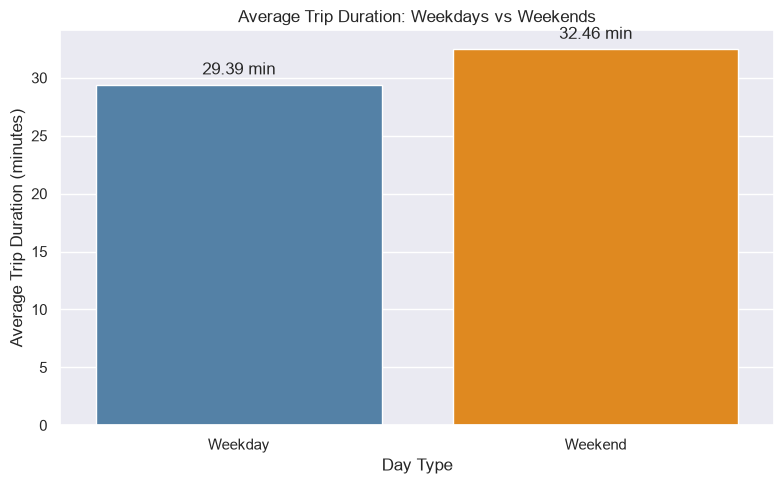

In [1090]:
# Compare average trip duration on weekdays and weekends
sns.set_theme(style="darkgrid")

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="is_weekend",
    y="duration_min",
    hue="is_weekend",
    estimator="mean",
    errorbar=None,
    palette=["steelblue", "darkorange"],
    legend=False
)

# Add values above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f min", padding=5)

plt.xticks([0, 1], ["Weekday", "Weekend"])
plt.xlabel("Day Type")
plt.ylabel("Average Trip Duration (minutes)")
plt.title("Average Trip Duration: Weekdays vs Weekends")

plt.tight_layout()

plt.savefig("Images/hypothesis_01_trip_duration.png")
plt.show()

Interpretation

The results support the hypothesis that trips are longer on weekends than on weekdays.

The average trip duration was 32.46 minutes on weekends, compared with 29.39 minutes on weekdays. The median duration was also higher on weekends (23.25 minutes versus 18.00 minutes). This suggests that weekend trips tend to last longer, and the difference is not explained by the mean alone.

At the same time, the dataset contains substantially more weekday trips (5,067) than weekend trips (2,044). One possible explanation is that some weekday trips are related to commuting or other short, routine journeys, while people may have more free time for leisure rides on weekends. However, the dataset does not identify trip purposes, so this explanation remains a hypothesis rather than a confirmed finding.

Unusually long trips may also affect the average duration. Therefore, both the mean and median were considered when comparing the two groups.

**Conclusion:** The hypothesis is supported by the observed data: trips are longer on weekends on average and at the median. 


## Hypothesis 2: Morning and Evening Peak Demand on Weekdays

### 1. Hypothesis

Weekdays have two distinct peaks in trip demand: one in the morning and another in the evening.

### 2. Metrics and Comparison Groups

- **Primary metric:** Number of trips by hour of the day.
- **Comparison group:** Weekday trips only.
- **Unit of observation:** One trip.
- **Relevant columns:** `hour`, `is_weekend`.

We will count trips for each hour from 0 to 23, considering weekdays only. This will help identify whether demand increases during typical morning and evening commuting hours.

### 3. Data Aggregation

We will group weekday trips by hour and calculate the number of trips starting in each hour. Hours with the highest trip counts will be examined to identify potential demand peaks.

### 4. Visualization

A line chart will show the number of weekday trips for each hour of the day. This will help us identify whether the data contains two distinct peaks.



In [1091]:
# Calculate hourly trip demand on weekdays

weekday_trips = df[df["is_weekend"] == False]

weekday_hourly_demand = (
    weekday_trips.groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
)

weekday_hourly_demand

hour
0       0
1       0
2       0
3       0
4       0
5       0
6      78
7     163
8     298
9     366
10    343
11    237
12    191
13    267
14    322
15    299
16    316
17    284
18    353
19    450
20    422
21    369
22    259
23    108
dtype: int64

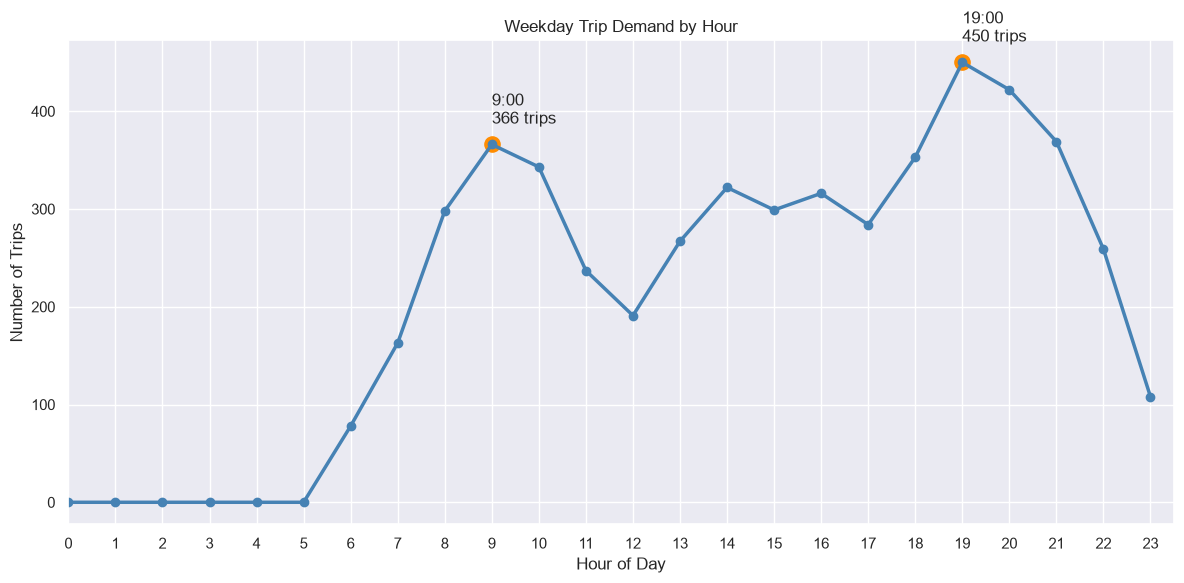

In [1092]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(12, 6))

plt.plot(weekday_hourly_demand.index, weekday_hourly_demand.values,
         marker="o", color="steelblue", linewidth=2.5)


# Highlight morning and evening peaks
for hour in [9, 19]:
    value = weekday_hourly_demand.loc[hour]
    plt.scatter(hour, value, color="darkorange", s=120)
    plt.annotate(f"{hour}:00\n{value} trips", (hour, value),
                 xytext=(0, 15), textcoords="offset points")

plt.xticks(range(24))
plt.xlim(0, 23.5)
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.title("Weekday Trip Demand by Hour")
plt.tight_layout()
plt.savefig("Images/hypothesis_02_weekday_hourly_demand.png")
plt.show()

###  Interpretation

The results show two main peaks in weekday trip demand. The highest number of trips was recorded at 9:00 AM (366 trips), while the evening peak occurred at 7:00 PM (450 trips).

We can also observe relatively high activity at 8:00 AM, 2:00 PM, and 4:00 PM. These patterns may be related to daily schedules. The morning activity could be associated with people travelling to work, school, or university, while the afternoon activity might reflect students returning home or travelling between classes. However, the dataset does not contain information about trip purposes, so these explanations remain assumptions.

This result can also be considered together with Hypothesis 1, which showed that weekend trips are longer on average than weekday trips. One possible explanation is that some weekday rides are shorter, routine journeys, while weekend rides may be more related to leisure activities.

**Conclusion:** The hypothesis is supported by the observed data, with clear morning and evening peaks in weekday trip demand. Additional activity at 8:00 AM, 2:00 PM, and 4:00 PM may reflect school, university, or work schedules.

## Hypothesis 3: Subscribers Take Shorter Trips Than Casual Users

### 1. Hypothesis
Subscribers have a shorter average trip duration than casual users.

### 2. Metrics and Comparison Groups
- **Primary metric:** Average trip duration in minutes.
- **Additional metric:** Median trip duration.
- **Comparison groups:** Subscribers and casual users.
- **Unit of observation:** One trip.
- **Relevant columns:** `user_type`, `duration_min`.

### 3. Data Aggregation
We will group trips by user type and calculate the number of trips, mean duration, and median duration.

### 4. Visualization
A bar chart will compare the average trip duration of subscribers and casual users. The mean and median will help us understand whether unusually long trips affect the results.

In [1093]:
# Compare trip duration by user type
user_duration = (
    df.groupby("user_type")["duration_min"]
    .agg(["count", "mean", "median"])
    .round(2)
)

user_duration

,count,mean,median
user_type,,,
Casual,2736,36.42,24.3
Subscriber,4375,26.43,16.8


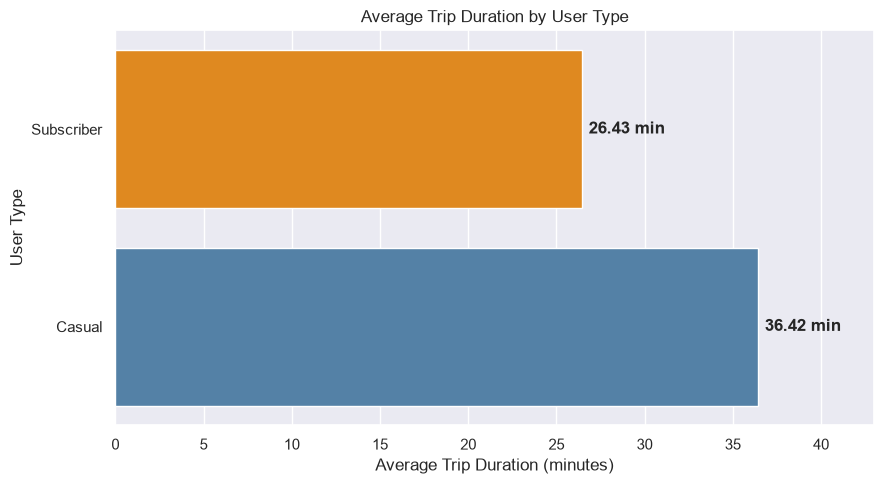

In [1094]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=df, x="duration_min", y="user_type",
    hue="user_type", palette=["darkorange", "steelblue"], errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f min", padding=5, fontweight="bold")

plt.xlabel("Average Trip Duration (minutes)")
plt.ylabel("User Type")
plt.title("Average Trip Duration by User Type")
plt.xlim(0, 43)
plt.tight_layout()
plt.savefig("Images/hypothesis_03_duration_by_user_type.png")
plt.show()

### Additional Analysis: Hourly Trip Demand by User Type

To better understand the differences between casual users and subscribers, we will compare the number of trips started at each hour of the day.

This analysis will help identify when each user group is most active and whether their usage patterns differ throughout the day.

- **Metric:** Number of trips per hour.
- **Comparison groups:** Casual and Subscriber.
- **Unit of observation:** One trip.
- **Relevant columns:** `user_type`, `hour`.

In [1095]:
# Compare hourly demand by user type
hourly_users = (
    df.groupby(["hour", "user_type"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(24), fill_value=0)
)

hourly_users

user_type,Casual,Subscriber
hour,,
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,48,62
7,87,143
8,157,268


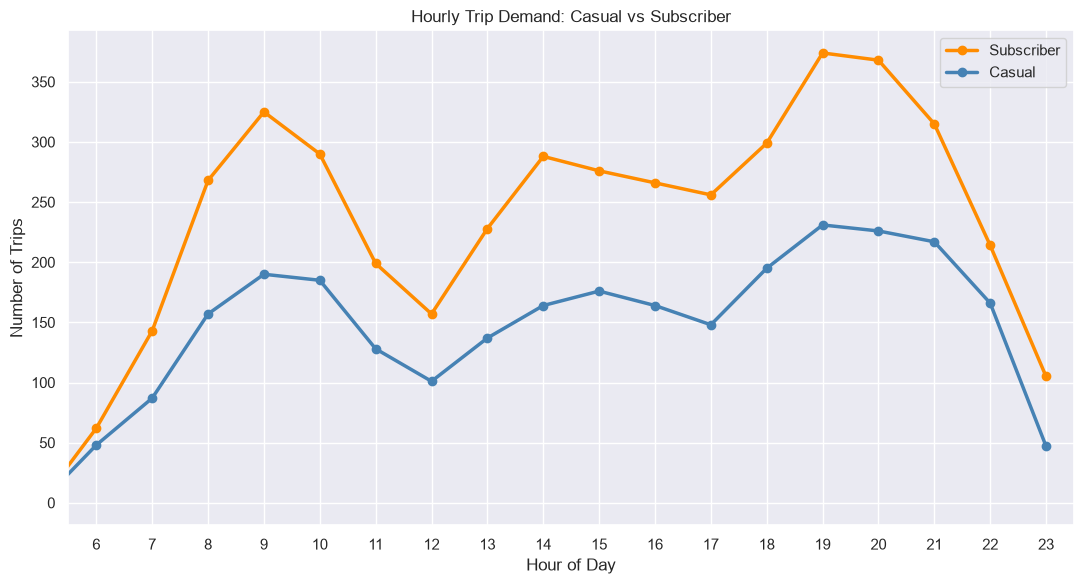

In [1096]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(11, 6))

plt.plot(hourly_users.index, hourly_users["Subscriber"],
         marker="o", color="darkorange", linewidth=2.5, label="Subscriber")

plt.plot(hourly_users.index, hourly_users["Casual"],
         marker="o", color="steelblue", linewidth=2.5, label="Casual")



plt.xticks(range(24))
plt.xlim(5.5, 23.5)
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.title("Hourly Trip Demand: Casual vs Subscriber")
plt.legend()
plt.tight_layout()
plt.savefig("Images/hypothesis_03_hourly_users.png", dpi=300)
plt.show()

### Interpretation

The results support the hypothesis that subscribers take shorter trips than casual users. The average trip duration was 26.43 minutes for subscribers and 36.42 minutes for casual users, a difference of 9.99 minutes.

To better understand these differences, we also compared hourly trip demand by user type. The results show that subscribers recorded more trips than casual users throughout the day. Both groups follow a similar daily pattern, with noticeable peaks around 9:00 AM and 7:00–8:00 PM. Subscriber activity is also relatively high around 2:00 PM.

One possible explanation is that subscribers use bicycles more frequently for routine activities, such as commuting to work or travelling around the city, while casual users may be more likely to take longer leisure rides. However, the dataset does not include trip purposes, so this explanation cannot be confirmed.

**Business recommendation:** The company could encourage casual users to become subscribers by offering trial memberships, discounts for the first month, or bonuses for frequent rides. Since casual users already use the service, these incentives could help convert some of them into regular subscribers.

**Conclusion:** Subscribers take shorter trips on average but account for more recorded trips. Their hourly usage pattern is consistent with more frequent, routine use of the service.

## Hypothesis 4: Electric Bikes Are Used for Longer Trips

### 1. Hypothesis
Electric bikes are used for longer trips than standard bikes.

### 2. Metrics and Comparison Groups
- **Primary metric:** Average trip distance in kilometers.
- **Additional metric:** Median trip distance.
- **Comparison groups:** Electric and Standard bikes.
- **Unit of observation:** One trip.
- **Relevant columns:** `bike_type`, `distance_km`.

### 3. Data Aggregation
We will group trips by bike type and calculate the number of trips, mean distance, and median distance.

### 4. Visualization
A horizontal bar chart will compare the average trip distance for electric and standard bikes. The median will provide an additional comparison that is less affected by unusually long trips.

In [1097]:
# Compare trip distance by bike type
bike_distance = (
    df.groupby("bike_type")["distance_km"]
    .agg(["count", "mean", "median"])
    .round(2)
)

bike_distance

,count,mean,median
bike_type,,,
Electric,1925,4.21,3.57
Standard,4946,3.13,2.61


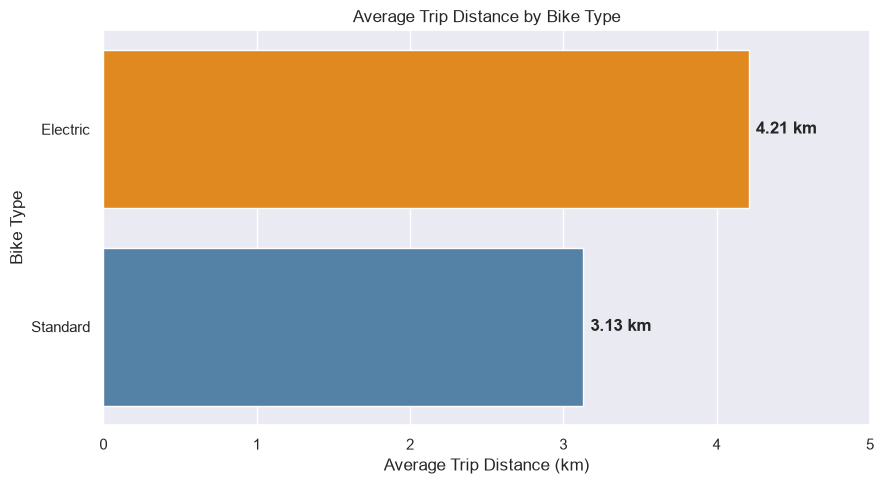

In [1098]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=df, x="distance_km", y="bike_type",
    hue="bike_type", palette=["darkorange", "steelblue"],
    errorbar=None,
    order=["Electric", "Standard"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f km", padding=5, fontweight="bold")

plt.xlabel("Average Trip Distance (km)")
plt.ylabel("Bike Type")
plt.title("Average Trip Distance by Bike Type")
plt.xlim(0, 5)
plt.tight_layout()
plt.savefig("Images/hypothesis_04_distance_by_bike_type.png")
plt.show()

### Interpretation

The results support the hypothesis that electric bikes are used for longer trips than standard bikes.

The average trip distance for electric bikes was 4.21 km, compared with 3.13 km for standard bikes. The median distance was also higher for electric bikes (3.57 km versus 2.61 km). This suggests that electric bikes tend to be used for longer journeys.

Another interesting finding is the difference in the number of recorded trips. There were 4,946 trips on standard bikes and 1,925 trips on electric bikes. This means that standard bikes were used approximately 2.6 times as often as electric bikes in this dataset.

Although this difference is not the main focus of the hypothesis, it provides additional insight into customer preferences. Standard bikes account for most recorded trips, while electric bikes are associated with longer average distances.

**Conclusion:** The hypothesis is supported. Electric bikes have a higher average and median trip distance, while standard bikes account for approximately 2.6 times as many recorded trips. However, the dataset does not explain why users choose one bike type over another.

## Hypothesis 5: Weather Conditions Are Associated with Bike Trip Demand

### 1. Hypothesis
The number of recorded bike trips is lower during rainy weather than during sunny or cloudy weather.

### 2. Metrics and Comparison Groups
- **Primary metric:** Number of recorded trips.
- **Additional metric:** Percentage of total trips for each weather condition.
- **Comparison groups:** Sunny, Cloudy, and Rainy weather.
- **Unit of observation:** One trip.
- **Relevant columns:** `weather`.

### 3. Data Aggregation
We will group all recorded trips by weather condition and count the number of trips in each category. We will then calculate the percentage of total trips represented by each weather condition.

This approach describes how recorded trips are distributed across weather conditions. However, it does not account for how frequently each type of weather occurred.

### 4. Visualization
Two pie charts will be displayed side by side. The first chart will show the number of trips for each weather condition, while the second will show the percentage share of total trips.




In [1099]:
# Compare trips by weather condition
weather_trips = (
    df.groupby("weather")
    .size()
    .sort_values(ascending=False)
)

weather_trips

weather
Sunny     4010
Cloudy    2070
Rainy     1120
dtype: int64

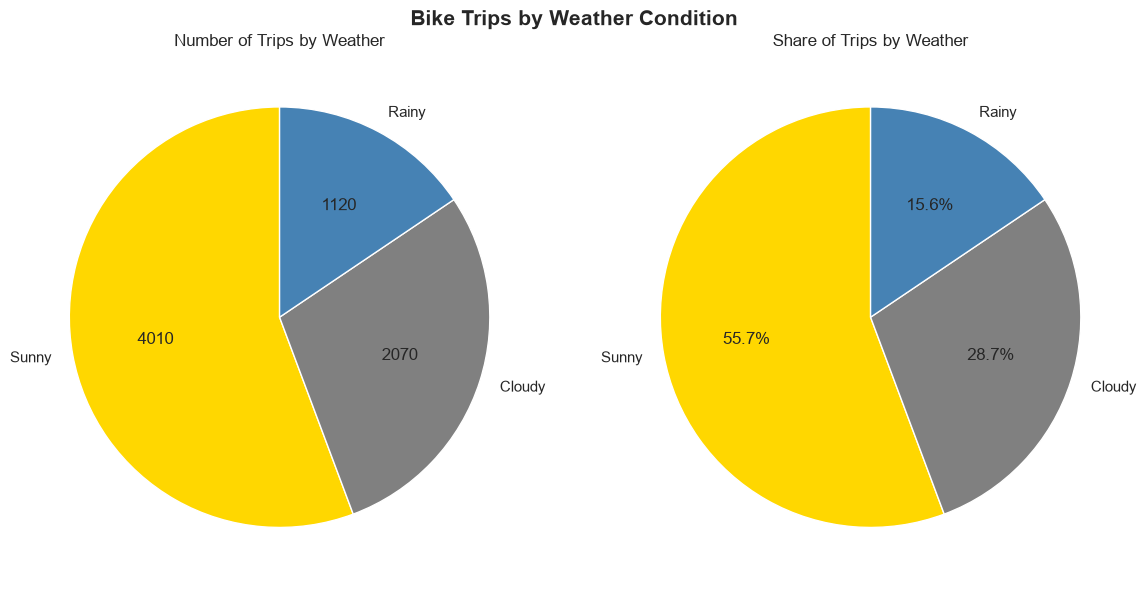

In [1100]:
# Compare trips by weather: counts and percentages
weather_trips = df["weather"].value_counts().reindex(
    ["Sunny", "Cloudy", "Rainy"]
)

colors = ["gold", "gray", "steelblue"]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].pie(
    weather_trips,
    labels=weather_trips.index,
    colors=colors,
    autopct=lambda p: f"{p * weather_trips.sum() / 100:.0f}",
    startangle=90
)
axes[0].set_title("Number of Trips by Weather")

axes[1].pie(
    weather_trips,
    labels=weather_trips.index,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Share of Trips by Weather")

plt.suptitle("Bike Trips by Weather Condition", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("Images/hypothesis_05_weather_pie_charts.png")
plt.show()

### Interpretation

The results show a clear difference in the distribution of bike trips across weather conditions.

Sunny weather accounted for 55.7% of all recorded trips (4,010 trips), while cloudy weather accounted for 28.8% (2,070 trips). Rainy weather had the lowest share, with only 15.6% of all recorded trips (1,120 trips).

These results are consistent with the hypothesis that bike trips are less common during rainy weather. The share of trips recorded in rainy conditions was much lower than in sunny conditions.

However, these percentages represent the distribution of recorded trips, not the average demand per day under each weather condition. Since the dataset does not account for how frequently each type of weather occurred, we cannot conclude that weather alone caused this difference.

**Conclusion:** The results support the hypothesis at the level of recorded trip distribution: rainy weather accounts for a substantially smaller share of trips than sunny or cloudy weather.

## Hypothesis 6: Higher Temperatures Are Associated with More Bike Trips

### 1. Hypothesis
Higher temperatures are associated with a higher number of bike trips per day.

### 2. Metrics and Comparison Groups
- **Primary metric:** Average number of trips per day.
- **Additional metric:** Total number of recorded trips.
- **Comparison groups:** Five temperature ranges.
- **Unit of observation:** One trip for the total count and one calendar day for the daily average.
- **Relevant columns:** `date`, `temperature_c`, `temperature_range`, `trip_id`.

### 3. Data Aggregation
We performed the analysis in two stages.

First, we divided recorded temperatures into five ranges and counted the total number of trips in each range. This helped us identify which temperature ranges accounted for the largest share of recorded trips.

Second, we calculated the average number of trips per day for each temperature range. This allowed us to compare daily trip counts and evaluate the hypothesis more directly.

### 4. Visualization
Two bar charts were created:
- The first chart shows the total number of trips recorded in each temperature range.
- The second chart shows the average number of trips per day for each temperature range.


In [1101]:
# Check minimum and maximum temperatures
print("Minimum temperature:", df["temperature_c"].min())
print("Maximum temperature:", df["temperature_c"].max())

Minimum temperature: -2.2
Maximum temperature: 42.7


In [1102]:
# Divide temperatures into five ranges
df["temperature_range"] = pd.cut(
    df["temperature_c"],
    bins=5
)

# Count trips in each temperature range
temperature_trips = (
    df["temperature_range"]
    .value_counts()
    .sort_index()
)

temperature_trips

temperature_range
(-2.245, 6.78]     125
(6.78, 15.76]     1587
(15.76, 24.74]    3642
(24.74, 33.72]    1648
(33.72, 42.7]       90
Name: count, dtype: int64

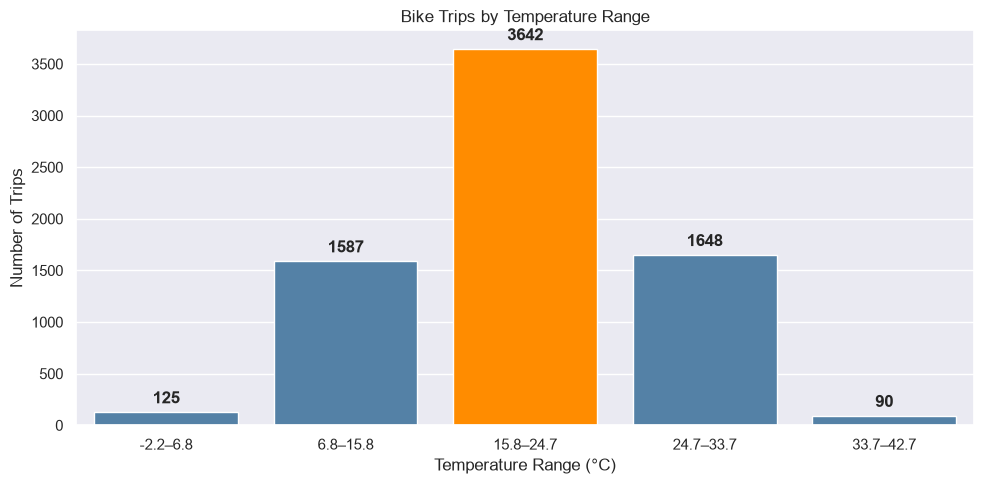

In [1103]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=temperature_trips.index.astype(str),
    y=temperature_trips.values,
    color="steelblue"
)

ax.patches[2].set_facecolor("darkorange")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4, fontweight="bold")

plt.xlabel("Temperature Range (°C)")
plt.ylabel("Number of Trips")
plt.title("Bike Trips by Temperature Range")
plt.xticks(
    range(len(temperature_trips)),
    [f"{x.left:.1f}–{x.right:.1f}" for x in temperature_trips.index]
)
plt.tight_layout()
plt.savefig("Images/hypothesis_06_trips_by_temperature.png")
plt.show()

In [1104]:
# Calculate daily trips by temperature range
daily_temp_trips = (
    df.groupby(["date", "temperature_range"], observed=True)
    .size()
    .unstack(fill_value=0)
)

# Average trips per day for each temperature range
avg_daily_temp_trips = daily_temp_trips.mean().round(2)

avg_daily_temp_trips

temperature_range
(-2.245, 6.78]     0.56
(6.78, 15.76]      7.08
(15.76, 24.74]    16.26
(24.74, 33.72]     7.36
(33.72, 42.7]      0.40
dtype: float64

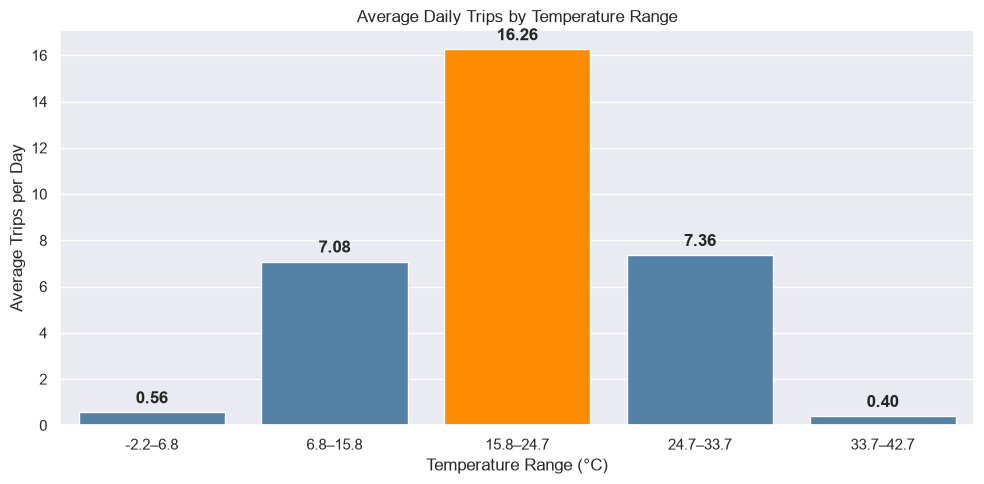

In [1105]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=avg_daily_temp_trips.index.astype(str),
    y=avg_daily_temp_trips.values,
    color="steelblue"
)

ax.patches[2].set_facecolor("darkorange")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4, fontweight="bold")

plt.xlabel("Temperature Range (°C)")
plt.ylabel("Average Trips per Day")
plt.title("Average Daily Trips by Temperature Range")
plt.xticks(
    range(len(avg_daily_temp_trips)),
    [f"{x.left:.1f}–{x.right:.1f}" for x in avg_daily_temp_trips.index]
)
plt.tight_layout()
plt.savefig("Images/hypothesis_06_average_daily_trips.png")
plt.show()

### Interpretation

The first chart shows the total number of trips recorded in each temperature range. The highest number of trips (3,642) was recorded between approximately 15.8°C and 24.7°C. In contrast, only 90 trips were recorded at temperatures above approximately 33.7°C.

The second chart provides a more direct comparison of daily trip counts. The highest average was also observed in the 15.8–24.7°C range, with approximately 16.26 trips per day. The average was much lower in the coldest and hottest ranges, at 0.56 and 0.40 trips per day, respectively.

These results suggest that moderate temperatures are associated with the highest recorded trip counts. However, the results do not support a simple linear relationship in which the number of trips continuously increases as temperature rises.

**Conclusion:** The hypothesis is partially supported. The highest trip counts were observed at moderate temperatures rather than at the highest temperatures. 

## Hypothesis 7: Republic Square Is the Most Popular Start Station

### 1. Hypothesis
Republic Square is the most popular starting station, with more trips starting there than at any other station.

### 2. Metrics and Comparison Groups
- **Primary metric:** Number of trips starting at each station.
- **Comparison groups:** All starting stations.
- **Unit of observation:** One trip.
- **Relevant columns:** `start_station`, `trip_id`.

### 3. Data Aggregation
We will count the number of trips starting at each station and rank the stations by trip count. Missing station names will be excluded from the comparison.

### 4. Visualization
A horizontal bar chart will display the ten most popular starting stations, with the most frequently used station highlighted.



In [1106]:
# Count trips by starting station
start_station_counts = (
    df["start_station"]
    .value_counts()
)

start_station_counts

start_station
Cascade            995
Republic Square    982
University         855
Arabkir Park       812
Opera              740
Komitas Market     693
Yerevan Mall       549
Barekamutyun       536
Victory Park       508
Erebuni            408
Name: count, dtype: int64

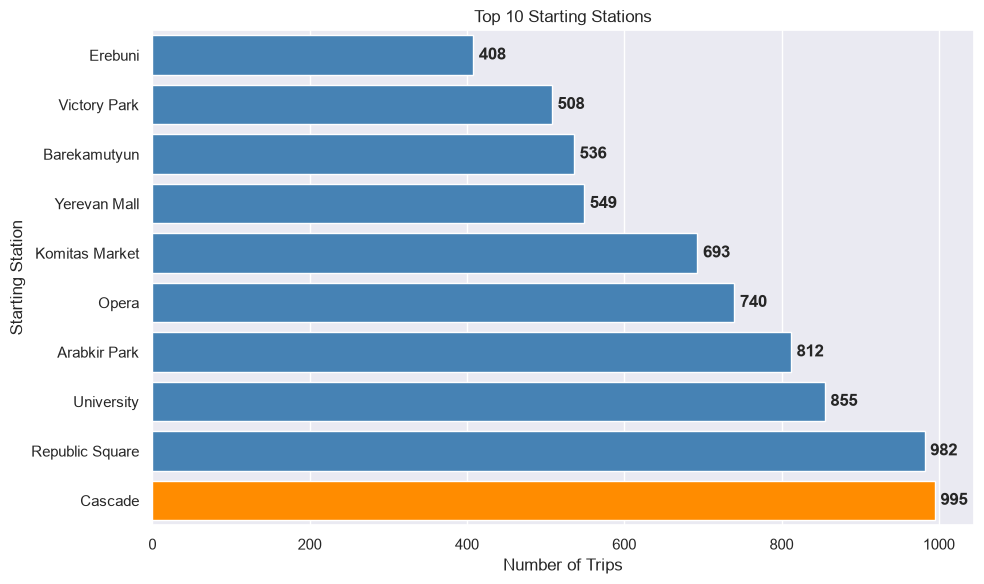

In [1107]:
sns.set_theme(style="darkgrid")

top_stations = start_station_counts.head(10).sort_values()

plt.figure(figsize=(10, 6))

colors = ["darkorange" if x == top_stations.max() else "steelblue"
          for x in top_stations.values]

ax = sns.barplot(x=top_stations.values, y=top_stations.index, color="steelblue")

for bar, color in zip(ax.patches, colors):
    bar.set_facecolor(color)

for container in ax.containers:
    ax.bar_label(container, padding=4, fontweight="bold")

plt.xlabel("Number of Trips")
plt.ylabel("Starting Station")
plt.title("Top 10 Starting Stations")
plt.tight_layout()
plt.savefig("Images/hypothesis_07_top_start_stations.png")
plt.show()

### Interpretation

The results do not support the hypothesis that Republic Square is the most popular starting station.

Cascade ranked first with 995 trips, while Republic Square ranked second with 982 trips. The difference between the two stations was only 13 trips, indicating that their popularity as starting locations was very similar.

**Conclusion:** Republic Square is the second most popular starting station in the dataset, while Cascade ranks first. Although the original hypothesis was not confirmed, Republic Square remains one of the most frequently used starting locations.

## Hypothesis 8: The Top 5 Starting and Ending Stations Differ Significantly

### 1. Hypothesis
The five most popular starting stations differ substantially from the five most popular ending stations.

### 2. Metrics and Comparison Groups
- **Primary metric:** Number of trips starting or ending at each station.
- **Comparison groups:** Top 5 starting stations and top 5 ending stations.
- **Unit of observation:** One trip.
- **Relevant columns:** `start_station`, `end_station`, `trip_id`.

### 3. Data Aggregation
We will count trips for each starting and ending station separately and identify the top five stations in each group. We will then compare the two lists to determine whether they contain different stations.

### 4. Visualization
A comparison chart will display the top five starting stations and top five ending stations, allowing us to compare their popularity and identify overlapping stations.


In [1108]:
# Compare the top 5 starting and ending stations
top_start = df["start_station"].value_counts().head(5)
top_end = df["end_station"].value_counts().head(5)

print("Top 5 Starting Stations:")
print(top_start)

print("\nTop 5 Ending Stations:")
print(top_end)

Top 5 Starting Stations:
start_station
Cascade            995
Republic Square    982
University         855
Arabkir Park       812
Opera              740
Name: count, dtype: int64

Top 5 Ending Stations:
end_station
Komitas Market     752
Arabkir Park       746
Republic Square    739
Opera              730
Victory Park       730
Name: count, dtype: int64


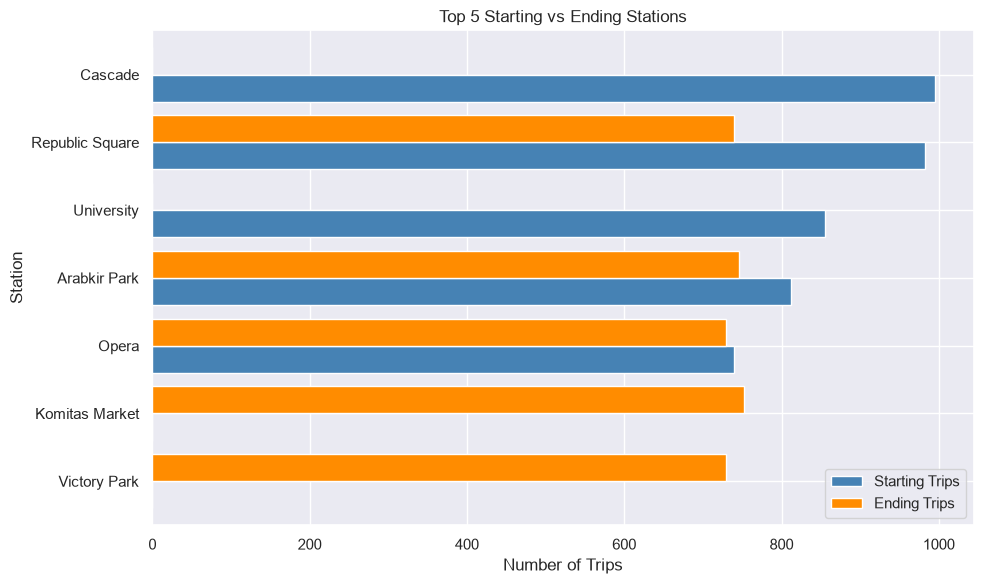

In [1109]:
# Compare the top 5 starting and ending stations
station_comparison = pd.concat([
    top_start.rename("Start"),
    top_end.rename("End")
], axis=1).fillna(0)

station_comparison = station_comparison.sort_values(
    "Start", ascending=True
)

station_comparison.plot(
    kind="barh",
    figsize=(10, 6),
    color=["steelblue", "darkorange"],
    width=0.8
)

plt.xlabel("Number of Trips")
plt.ylabel("Station")
plt.title("Top 5 Starting vs Ending Stations")
plt.legend(["Starting Trips", "Ending Trips"])
plt.tight_layout()
plt.savefig("Images/hypothesis_08_start_vs_end_stations.png")
plt.show()

### Interpretation

The results support the hypothesis that the top five starting stations differ from the top five ending stations.

The two rankings overlap partially, but they are not identical. Cascade and University appear among the top five starting stations but are absent from the top five ending stations. In contrast, Komitas Market and Victory Park appear among the top five ending stations but not among the top five starting stations.

Some stations, including Republic Square, Arabkir Park, and Opera, appear in both rankings. This suggests that certain locations are popular for both starting and ending trips, while others are more prominent in only one ranking.

**Conclusion:** The hypothesis is supported because the top five starting and ending stations differ in their composition. 

## Hypothesis 9: Weekday Trips Peak in the Morning, While Weekend Trips Peak in the Afternoon

### 1. Hypothesis
Weekday trips are more concentrated in the morning, while weekend trips are more concentrated in the afternoon.

### 2. Metrics and Comparison Groups
- **Primary metric:** Number of trips by time of day.
- **Comparison groups:** Weekdays and weekends.
- **Time categories:** Morning, Afternoon, Evening, and Night.
- **Unit of observation:** One trip.
- **Relevant columns:** `is_weekend`, `time_of_day`, `trip_id`.

### 3. Data Aggregation
We will count trips for each time-of-day category separately for weekdays and weekends. We will also compare the distribution of trips within each day type to account for the different total numbers of weekday and weekend trips.

### 4. Visualization
A grouped bar chart will compare weekday and weekend trip counts across the four time-of-day categories.


In [1110]:
# Compare trips by day type and time of day
time_comparison = (
    df.groupby(["time_of_day", "is_weekend"])
    .size()
    .unstack(fill_value=0)
)

time_comparison.columns = ["Weekday", "Weekend"]
time_comparison

,Weekday,Weekend
time_of_day,,
Afternoon,1395,562
Evening,1509,588
Morning,1485,597
Night,736,328


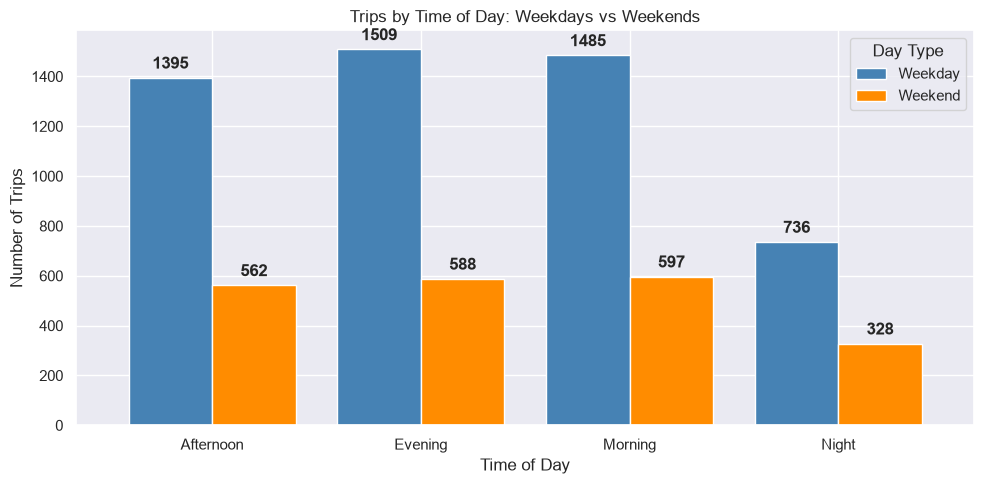

In [1111]:
sns.set_theme(style="darkgrid")

ax = time_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "darkorange"],
    width=0.8
)

for container in ax.containers:
    ax.bar_label(container, padding=4, fontweight="bold")

plt.xlabel("Time of Day")
plt.ylabel("Number of Trips")
plt.title("Trips by Time of Day: Weekdays vs Weekends")
plt.xticks(rotation=0)
plt.legend(title="Day Type")
plt.tight_layout()
plt.savefig("Images/hypothesis_09_trips_by_time.png")
plt.show()

### Interpretation

The results do not support the original hypothesis.

On weekdays, the highest number of trips was recorded in the evening (1,509 trips), followed by the morning (1,485 trips). This suggests that weekday demand is slightly higher in the evening than in the morning.

On weekends, the highest number of trips occurred in the morning (597 trips), closely followed by the evening (588 trips). The difference between these two periods is small, so morning and evening activity on weekends is very similar.

One possible explanation is that weekday evening trips may be related to people returning from work, while weekend morning trips may be associated with leisure activities. However, the dataset does not identify trip purposes, so these explanations remain assumptions.

**Conclusion:** The hypothesis is not fully supported. Weekday trips peak in the evening rather than in the morning, while weekend trips peak in the morning, although the difference between morning and evening is small.

## Hypothesis 10: Trip Price Is Positively Related to Distance

### 1. Hypothesis
Longer trips tend to have a higher price than shorter trips.

### 2. Metrics and Comparison Groups
- **Primary metric:** Trip price in AMD.
- **Explanatory variable:** Trip distance in kilometers.
- **Unit of observation:** One trip.
- **Relevant columns:** `distance_km`, `price_amd`.

### 3. Data Aggregation
We will examine the relationship between trip distance and price using records with valid values for both variables. We will calculate the correlation coefficient to measure the direction and strength of the relationship.

### 4. Visualization
A scatter plot will show trip distance against price. A trend line will help us identify whether prices generally increase as trip distance increases.



In [1112]:
# Check the relationship between distance and price
price_distance = df[["distance_km", "price_amd"]].dropna()

print("Valid trips:", len(price_distance))
print("Correlation:", round(
    price_distance["distance_km"].corr(price_distance["price_amd"]), 3
))

Valid trips: 6827
Correlation: 0.663


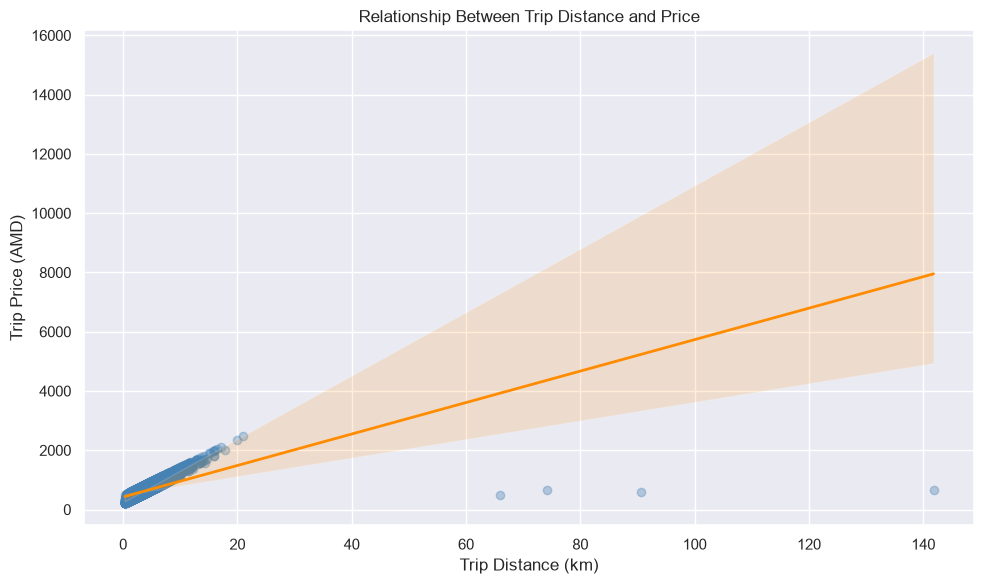

In [1113]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(10, 6))

sns.regplot(
    data=price_distance,
    x="distance_km",
    y="price_amd",
    scatter_kws={"alpha": 0.35, "color": "steelblue"},
    line_kws={"color": "darkorange", "linewidth": 2}
)

plt.xlabel("Trip Distance (km)")
plt.ylabel("Trip Price (AMD)")
plt.title("Relationship Between Trip Distance and Price")
plt.tight_layout()
plt.savefig("Images/hypothesis_10_price_vs_distance.png")
plt.show()

In [1114]:
# Inspect trips longer than 50 km
price_distance[price_distance["distance_km"] > 50].sort_values(
    "distance_km"
)

,distance_km,price_amd
2285,66.0,494.0
4994,74.1,653.0
7325,90.6,589.0
2557,141.8,667.0


In [1115]:
# Compare correlation with and without long trips
price_distance_clean = price_distance[
    price_distance["distance_km"] <= 50
]

print("Original correlation:",
      round(price_distance["distance_km"].corr(price_distance["price_amd"]), 3))

print("Correlation without trips over 50 km:",
      round(price_distance_clean["distance_km"].corr(
          price_distance_clean["price_amd"]), 3))

print("Removed from comparison:",
      len(price_distance) - len(price_distance_clean))

Original correlation: 0.663
Correlation without trips over 50 km: 0.944
Removed from comparison: 4


In [1116]:
# Inspect the four unusually long trips
df.loc[
    df["distance_km"] > 50
].T

,2285,2557,4994,7325
trip_id,B206217,B200982,B207037,B200764
started_at,2026-09-03 11:22:00,2026-05-05 15:04:00,2026-07-18 21:52:00,2026-08-30 17:14:00
date,2026-09-03,2026-05-05,2026-07-18,2026-08-30
month,9,5,7,8
hour,11,15,21,17
weekday,Thursday,Tuesday,Saturday,Sunday
is_weekend,False,False,True,True
time_of_day,Morning,Afternoon,Night,Evening
start_station,Arabkir Park,Victory Park,Erebuni,Republic Square
end_station,University,Cascade,Yerevan Mall,Komitas Market


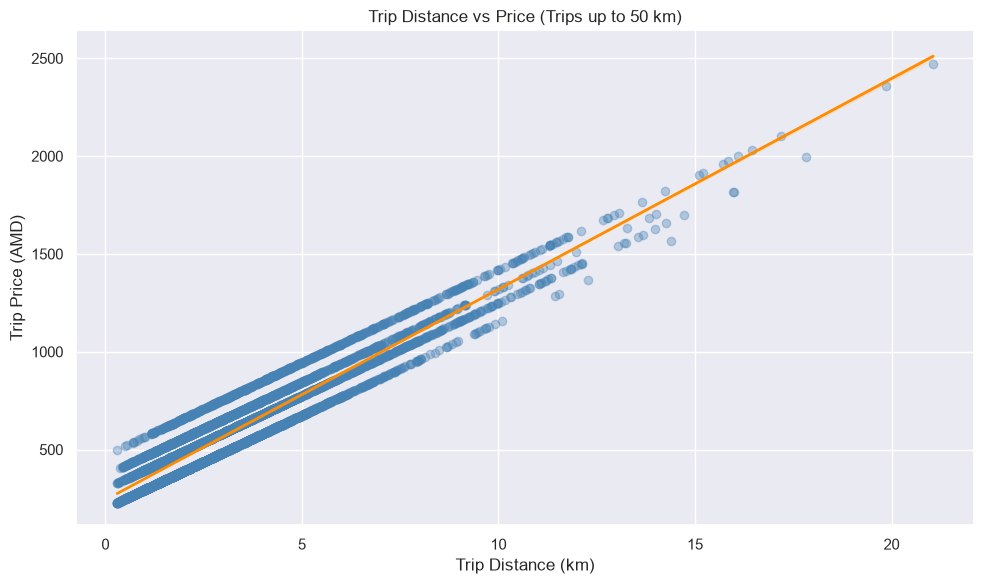

In [1117]:
# Plot distance and price without trips over 50 km
plt.figure(figsize=(10, 6))

sns.regplot(
    data=price_distance_clean,
    x="distance_km",
    y="price_amd",
    scatter_kws={"alpha": 0.35, "color": "steelblue"},
    line_kws={"color": "darkorange", "linewidth": 2}
)

plt.xlabel("Trip Distance (km)")
plt.ylabel("Trip Price (AMD)")
plt.title("Trip Distance vs Price (Trips up to 50 km)")
plt.tight_layout()
plt.savefig("Images/hypothesis_10_price_vs_distance_clean.png")
plt.show()

###  Interpretation

The first scatter plot showed a positive relationship between trip distance and price, with four unusual observations representing trips longer than 50 km. These trips had relatively low prices compared with the general trend.

We investigated these four records individually. Their distances and other available information did not provide sufficient evidence that the records were incorrect. Although the prices seemed unusually low for such long trips, we do not know the pricing rules or whether these customers received discounts. Therefore, we cannot conclude that the prices are erroneous, and we decided to keep all four records in the dataset.

To better examine the relationship between distance and price, we created a second scatter plot excluding these four trips from the comparison. The correlation increased from 0.663 to 0.944, making the positive linear relationship more apparent.

**Conclusion:** The hypothesis is supported. Trip distance and price have a positive relationship, and longer trips generally tend to cost more. However, the four unusual observations weaken the overall linear correlation. Since we cannot confirm that these records are incorrect, they remain in the original dataset, and the second scatter plot is used only as an additional comparison.

## Hypothesis 11: Casual Users Pay More per Trip Than Subscribers

### 1. Hypothesis
Casual users pay more per trip on average than Subscribers.

### 2. Metrics and Comparison Groups
- **Primary metric:** Average trip price in AMD.
- **Additional metric:** Median trip price in AMD.
- **Comparison groups:** Casual and Subscriber users.
- **Unit of observation:** One trip.
- **Relevant columns:** `user_type`, `price_amd`.

### 3. Data Aggregation
We will group trips by user type and calculate the number of valid prices, mean price, and median price for each group. The median will provide an additional comparison that is less affected by unusually high or low prices.

### 4. Visualization
A bar chart will compare the average trip price for Casual and Subscriber users. Labels will show the average price for each group.



In [1118]:
# Compare trip prices by user type
price_by_user = (
    df.groupby("user_type")["price_amd"]
    .agg(["count", "mean", "median"])
    .round(2)
)

price_by_user

,count,mean,median
user_type,,,
Casual,2739,737.08,680.0
Subscriber,4416,525.77,479.5


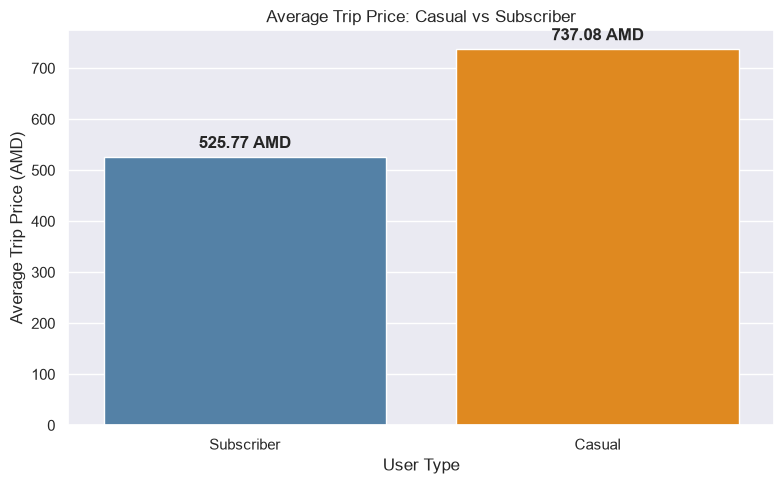

In [1119]:
sns.set_theme(style="darkgrid")

price_plot = price_by_user.loc[["Subscriber", "Casual"]]

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=price_plot.index,
    y=price_plot["mean"],
    hue=price_plot.index,
    palette=["steelblue", "darkorange"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f AMD", padding=4, fontweight="bold")

plt.xlabel("User Type")
plt.ylabel("Average Trip Price (AMD)")
plt.title("Average Trip Price: Casual vs Subscriber")
plt.tight_layout()
plt.savefig("Images/hypothesis_11_price_by_user_type.png")
plt.show()

###  Interpretation

The results support the hypothesis that Casual users pay more per trip than Subscribers.

The average trip price for Casual users was 737.08 AMD, compared with 525.77 AMD for Subscribers. The median price was also higher for Casual users (680 AMD versus 479.50 AMD).

This difference is consistent with the results of Hypothesis 3, which showed that Casual users have longer trips on average (36.42 minutes) than Subscribers (26.43 minutes). Longer trips may contribute to the higher average price, although the relationship between duration and price was not directly tested here.

The dataset also contains more recorded Subscriber trips with valid prices (4,416) than Casual trips (2,739).

**Conclusion:** The hypothesis is supported. Casual users pay more per trip on average and at the median. These findings suggest that Subscribers may benefit from more affordable trips, while Casual users may be a potential target group for subscription offers.

## Hypothesis 12: Electric Bikes Have More Technical Issues

### 1. Hypothesis
Electric bikes have a higher rate of reported technical issues than standard bikes.

### 2. Metrics and Comparison Groups
- **Primary metric:** Percentage of trips with a reported technical issue.
- **Additional metric:** Number of trips with technical issues.
- **Comparison groups:** Electric and Standard bikes.
- **Unit of observation:** One trip.
- **Relevant columns:** `bike_type`, `technical_issue`, `trip_id`.

### 3. Data Aggregation
We will group trips by bike type and calculate the total number of trips, the number of reported technical issues, and the percentage of trips with technical issues.

### 4. Visualization
A bar chart will compare the percentage of trips with technical issues for Electric and Standard bikes.



In [1120]:
# Compare technical issues by bike type
issue_comparison = (
    df.groupby("bike_type")
    .agg(
        trips=("trip_id", "count"),
        issues=("technical_issue", lambda x: (x == "Yes").sum())
    )
)

issue_comparison["issue_rate"] = (
    issue_comparison["issues"] / issue_comparison["trips"] * 100
).round(2)

issue_comparison

,trips,issues,issue_rate
bike_type,,,
Electric,2025,104,5.14
Standard,5175,124,2.40


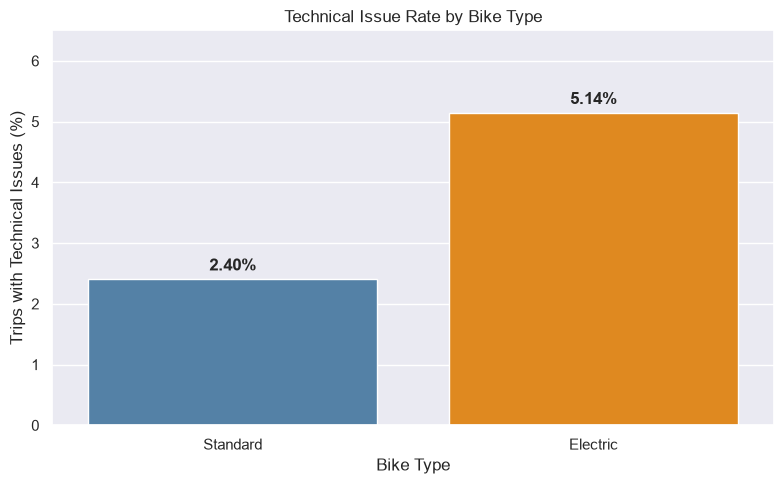

In [1121]:
sns.set_theme(style="darkgrid")

issue_plot = issue_comparison.loc[["Standard", "Electric"]]

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=issue_plot.index,
    y=issue_plot["issue_rate"],
    hue=issue_plot.index,
    palette=["steelblue", "darkorange"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4, fontweight="bold")

plt.xlabel("Bike Type")
plt.ylabel("Trips with Technical Issues (%)")
plt.title("Technical Issue Rate by Bike Type")
plt.ylim(0, 6.5)
plt.tight_layout()
plt.savefig("Images/hypothesis_12_technical_issues.png")
plt.show()

###  Interpretation

The results support the hypothesis that electric bikes have a higher rate of reported technical issues than standard bikes.

Among electric bike trips, 104 out of 2,025 trips had a reported technical issue, representing 5.14%. For standard bikes, 124 out of 5,175 trips had a reported issue, representing 2.40%.

Although more technical issues were recorded for standard bikes in absolute numbers, electric bikes had a higher issue rate. The rate for electric bikes was approximately 2.14 times that of standard bikes.

**Conclusion:** The hypothesis is supported by the observed data. Electric bike trips had a substantially higher reported technical issue rate. 

## Hypothesis 13: Trips in Rainy Weather Receive Lower Ratings Than Trips in Sunny Weather

### 1. Hypothesis
Trips taken in rainy weather receive lower user ratings than trips taken in sunny weather.

### 2. Metrics and Comparison Groups
- **Primary metric:** Average trip rating.
- **Additional metric:** Median trip rating.
- **Comparison groups:** Rainy and Sunny weather.
- **Unit of observation:** One trip with a valid rating.
- **Relevant columns:** `weather`, `rating`.

### 3. Data Aggregation
We will group trips by weather condition and calculate the number of valid ratings, the mean rating, and the median rating. We will compare rainy and sunny trips to evaluate whether ratings are lower in rainy conditions.

### 4. Visualization
A bar chart will compare the average ratings for rainy and sunny trips, with labels showing the mean rating for each weather condition.



In [1122]:
# Compare trip ratings by weather
rating_by_weather = (
    df[df["weather"].isin(["Rainy", "Sunny"])]
    .groupby("weather")["rating"]
    .agg(["count", "mean", "median"])
    .round(2)
)

rating_by_weather

,count,mean,median
weather,,,
Rainy,933,4.19,4.0
Sunny,3363,4.45,5.0


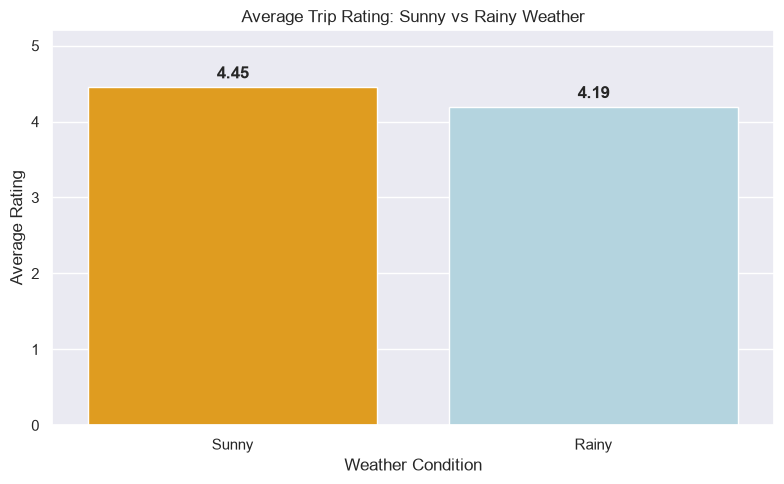

In [1123]:
sns.set_theme(style="darkgrid")

rating_plot = rating_by_weather.loc[["Sunny", "Rainy"]]

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=rating_plot.index,
    y=rating_plot["mean"],
    hue=rating_plot.index,
    palette=["orange", "lightblue"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4, fontweight="bold")

plt.xlabel("Weather Condition")
plt.ylabel("Average Rating")
plt.title("Average Trip Rating: Sunny vs Rainy Weather")
plt.ylim(0, 5.2)
plt.tight_layout()
plt.savefig("Images/hypothesis_13_rating_by_weather.png")
plt.show()

###  Interpretation

The results support the hypothesis that trips in rainy weather receive lower ratings than trips in sunny weather.

The average rating for rainy trips was 4.19, compared with 4.45 for sunny trips. The median rating was also lower in rainy weather (4.0 versus 5.0).

These results suggest that users tend to give lower ratings to trips recorded during rainy weather. Uncomfortable riding conditions may be one possible explanation, although the dataset does not establish the reasons behind the difference.

**Conclusion:** The hypothesis is supported by the observed ratings. Both the mean and median ratings were lower for rainy trips than for sunny trips. However, this comparison shows an association and does not prove that rain directly causes lower ratings.

## Hypothesis 14: Trip Duration Differs Across Age Groups

### 1. Hypothesis
Average trip duration differs across age groups.

### 2. Metrics and Comparison Groups
- **Primary metric:** Average trip duration in minutes.
- **Additional metric:** Median trip duration in minutes.
- **Comparison groups:** Under 18, 18–29, 30–44, 45–59, and 60+.
- **Unit of observation:** One trip with a valid duration and age group.
- **Relevant columns:** `age_group`, `duration_min`.

### 3. Data Aggregation
We will group trips by age group and calculate the number of valid trips, mean duration, and median duration. The median will help us compare typical trip durations while reducing the influence of unusually long trips.

### 4. Visualization
A bar chart will compare the average trip duration across age groups, with labels showing the mean duration for each group.



In [1124]:
# Compare trip duration by age group
duration_by_age = (
    df.groupby("age_group")["duration_min"]
    .agg(["count", "mean", "median"])
    .round(2)
)

duration_by_age

,count,mean,median
age_group,,,
18-29,1579,30.96,19.40
30-44,1939,29.34,19.10
45-59,1892,29.47,19.15
60+,1222,33.16,19.10
Under 18,256,25.20,20.30
Unknown,223,30.41,19.40


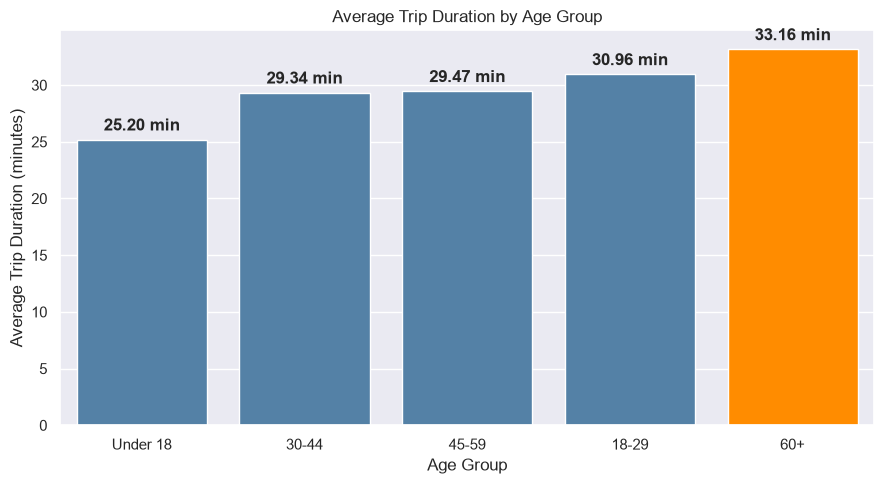

In [1125]:
sns.set_theme(style="darkgrid")

age_plot = duration_by_age.drop(index="Unknown").sort_values("mean")

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=age_plot.index,
    y=age_plot["mean"],
    color="steelblue"
)

ax.patches[-1].set_facecolor("darkorange")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f min", padding=4, fontweight="bold")

plt.xlabel("Age Group")
plt.ylabel("Average Trip Duration (minutes)")
plt.title("Average Trip Duration by Age Group")
plt.tight_layout()
plt.savefig("Images/hypothesis_14_duration_by_age.png")
plt.show()

###  Interpretation

The results show some differences in trip duration across age groups, but the differences are relatively moderate.

Users aged 60 and above had the longest average trip duration at 33.16 minutes, followed by users aged 18–29 at 30.96 minutes. Users aged 30–44 and 45–59 had similar average durations of 29.34 and 29.47 minutes, respectively. The Under 18 group had the shortest average duration at 25.20 minutes.

However, the median duration was similar across most age groups, ranging from 19.10 to 19.40 minutes, except for the Under 18 group, whose median was 20.30 minutes. This suggests that unusually long trips may influence the differences in average duration.

**Conclusion:** The results show some variation in average trip duration across age groups, but there is no clear pattern of large differences across most groups. The hypothesis is partially supported by the observed variation, although the median values suggest that typical trip durations are quite similar.

## Hypothesis 15: Popular Starting Stations Change from Month to Month

### 1. Hypothesis
The most popular starting stations vary from month to month.

### 2. Metrics and Comparison Groups
- **Primary metric:** Number of trips starting at each station per month.
- **Comparison groups:** Months from March to September 2026.
- **Unit of observation:** One trip.
- **Relevant columns:** `month`, `start_station`, `trip_id`.

### 3. Data Aggregation
We will count trips for each starting station in each month and identify the three most popular stations per month. We will compare the monthly rankings to see whether the most popular stations change over time.

### 4. Visualization
A line chart will show the monthly number of trips for the most popular starting stations, allowing us to compare changes in their popularity over time.



In [1126]:
# Count trips by starting station and month
monthly_stations = (
    df.groupby(["month", "start_station"])
    .size()
    .unstack(fill_value=0)
)

monthly_stations

start_station,Arabkir Park,Barekamutyun,Cascade,Erebuni,Komitas Market,Opera,Republic Square,University,Victory Park,Yerevan Mall
month,,,,,,,,,,
1,0,0,0,0,0,1,0,0,0,1
2,0,0,0,0,2,0,0,0,2,0
3,107,73,156,69,97,97,140,119,75,76
4,110,76,153,40,94,112,127,137,73,79
5,105,80,127,64,108,105,171,136,75,80
6,118,78,126,59,98,99,137,146,64,75
7,117,80,146,59,82,121,124,96,80,82
8,135,78,140,53,111,116,147,122,63,77
9,119,71,146,64,101,88,134,99,76,79


In [1127]:
# Check the trip date range
print("Earliest date:", df["started_at"].min())
print("Latest date:", df["started_at"].max())

print("\nTrips by month:")
print(df["month"].value_counts().sort_index())

Earliest date: 2026-01-03 12:49:00
Latest date: 2026-12-08 22:24:00

Trips by month:
month
1        2
2        4
3     1031
4     1013
5     1068
6     1017
7     1008
8     1054
9      998
10       2
11       2
12       1
Name: count, dtype: int64


In [1128]:
# Inspect trips outside the expected period
df[~df["month"].between(3, 9)].sort_values("started_at")

,trip_id,started_at,date,month,hour,weekday,is_weekend,time_of_day,start_station,end_station,...,duration_min,distance_km,speed_kmh,price_amd,rating,technical_issue,user_age,age_group,is_weekend_reported,temperature_range
1870,B204287,2026-01-03 12:49:00,2026-01-03,1,12,Saturday,True,Afternoon,Opera,Komitas Market,...,17.4,3.02,10.4,487.0,4.0,No,57.0,45-59,yes,"(6.78, 15.76]"
6766,B203336,2026-01-04 18:25:00,2026-01-04,1,18,Sunday,True,Evening,Yerevan Mall,Arabkir Park,...,18.2,3.65,12.0,717.0,4.0,No,45.0,45-59,yes,"(15.76, 24.74]"
4118,B207164,2026-02-04 20:26:00,2026-02-04,2,20,Wednesday,False,Evening,Victory Park,Opera,...,57.3,9.98,10.5,1248.0,4.0,No,36.0,30-44,no,"(6.78, 15.76]"
5228,B204376,2026-02-05 09:28:00,2026-02-05,2,9,Thursday,False,Morning,Victory Park,Erebuni,...,10.3,1.77,10.3,368.0,5.0,No,42.0,30-44,no,"(24.74, 33.72]"
1392,B207111,2026-02-05 13:11:00,2026-02-05,2,13,Thursday,False,Afternoon,Komitas Market,Arabkir Park,...,18.6,2.95,9.5,580.0,5.0,No,38.0,30-44,no,"(15.76, 24.74]"
5252,B205236,2026-02-06 13:39:00,2026-02-06,2,13,Friday,False,Afternoon,Komitas Market,Cascade,...,10.0,1.79,10.7,370.0,NaN,No,25.0,18-29,no,"(15.76, 24.74]"
5066,B201835,2026-10-04 20:21:00,2026-10-04,10,20,Sunday,True,Evening,Republic Square,Victory Park,...,9.2,1.64,10.7,356.0,5.0,No,48.0,45-59,yes,"(6.78, 15.76]"
781,B200070,2026-10-07 11:38:00,2026-10-07,10,11,Wednesday,False,Morning,Cascade,Arabkir Park,...,5.8,0.65,6.7,262.0,5.0,No,47.0,45-59,no,"(15.76, 24.74]"
1488,B206861,2026-11-05 14:32:00,2026-11-05,11,14,Thursday,False,Afternoon,Republic Square,Yerevan Mall,...,23.7,2.81,7.1,467.0,4.0,No,51.0,45-59,no,"(15.76, 24.74]"
2160,B202845,2026-11-09 14:20:00,2026-11-09,11,14,Monday,False,Afternoon,Opera,Komitas Market,...,17.4,1.83,6.3,374.0,3.0,No,66.0,60+,no,"(6.78, 15.76]"


In [1129]:
# Select the top 5 starting stations
main_stations = (
    df[df["month"].between(3, 9)]["start_station"]
    .value_counts()
    .head(5)
    .index
)

monthly_top5 = monthly_stations.loc[3:9, main_stations]
monthly_top5

start_station,Cascade,Republic Square,University,Arabkir Park,Opera
month,,,,,
3,156,140,119,107,97
4,153,127,137,110,112
5,127,171,136,105,105
6,126,137,146,118,99
7,146,124,96,117,121
8,140,147,122,135,116
9,146,134,99,119,88


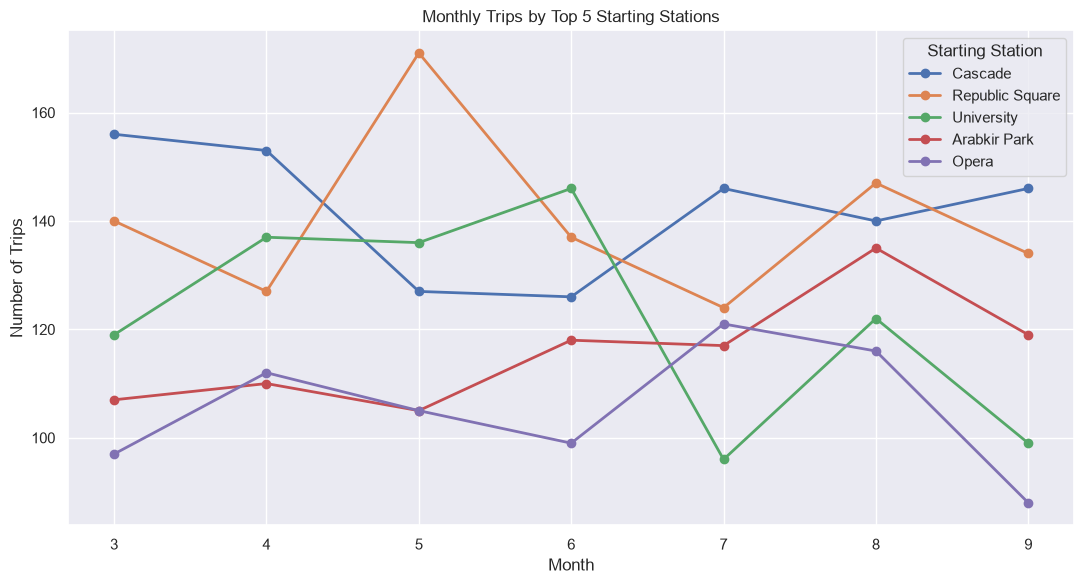

In [1130]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(11, 6))

for station in monthly_top5.columns:
    plt.plot(monthly_top5.index, monthly_top5[station],
             marker="o", linewidth=2, label=station)

plt.xticks(range(3, 10))
plt.xlabel("Month")
plt.ylabel("Number of Trips")
plt.title("Monthly Trips by Top 5 Starting Stations")
plt.legend(title="Starting Station")
plt.tight_layout()
plt.savefig("Images/hypothesis_15_monthly_stations.png")
plt.show()

###  Interpretation

The results show that the number of trips from popular starting stations changes from month to month. However, the most popular stations do not follow exactly the same pattern.

Cascade was the most frequently used starting station in March and April, with 156 and 153 trips, respectively. In May, Republic Square became the most popular station, recording 171 trips. University also showed noticeable changes, reaching 146 trips in June before dropping to 96 in July. These variations suggest that the popularity of starting stations changes over time.

However, the overall patterns are not consistent enough to conclude that every station experiences a clear seasonal trend. The chart compares the five most popular starting stations across the main observation period, from March to September 2026.

During data validation, we also discovered 11 trips outside this period: two in January, four in February, two in October, two in November, and one in December 2026. The earliest recorded trip was on January 3, 2026, and the latest was on December 8, 2026.

We inspected these records and found no clear evidence that the trips themselves were invalid. Although the dates may represent test rides or other activities outside the main operating period, this explanation cannot be confirmed using the available data.

Therefore, we retained these 11 records instead of deleting them or replacing their timestamps with missing values. This preserves the original information and avoids making unsupported assumptions about why the dates fall outside the main observation period.

For this hypothesis, we limited the monthly comparison to March–September 2026 to focus on the main observation period. The 11 out-of-period records were excluded from this particular comparison, but they remain in the original dataset.

**Conclusion:** The hypothesis is partially supported. The number of trips from popular starting stations varies across months, and the most popular station can change. However, the observed differences do not establish a clear seasonal pattern or explain why station popularity changes. 

## Hypothesis 16: Average Speed Differs by Bike Type

### 1. Hypothesis
Average trip speed differs between electric and standard bikes.

### 2. Metrics and Comparison Groups
- **Primary metric:** Average trip speed in km/h.
- **Additional metric:** Median trip speed in km/h.
- **Comparison groups:** Electric and Standard bikes.
- **Unit of observation:** One trip with a valid calculated speed.
- **Relevant columns:** `bike_type`, `speed_kmh`.

### 3. Data Aggregation
We will group trips by bike type and calculate the number of trips with valid speed values, mean speed, and median speed.

### 4. Visualization
A bar chart will compare the average speed of electric and standard bikes, with labels showing the mean speed for each group.



In [1131]:
# Compare trip speed by bike type
speed_by_bike = (
    df.groupby("bike_type")["speed_kmh"]
    .agg(["count", "mean", "median"])
    .round(2)
)

speed_by_bike

,count,mean,median
bike_type,,,
Electric,1923,15.01,10.2
Standard,4938,15.31,8.7


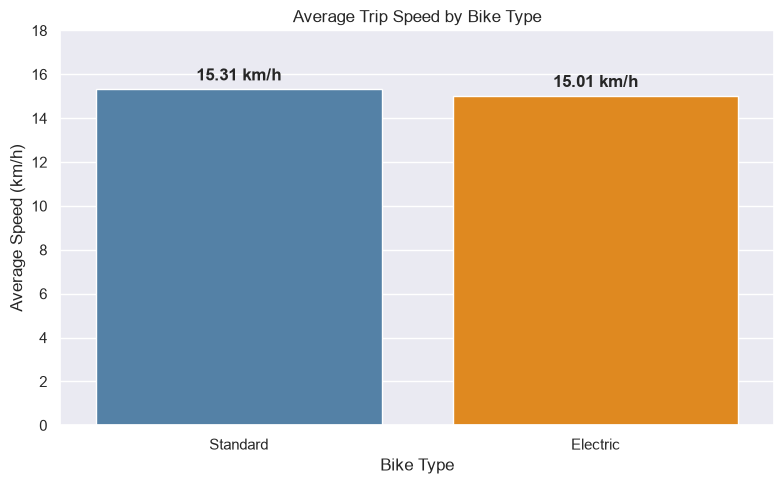

In [1132]:
sns.set_theme(style="darkgrid")

speed_plot = speed_by_bike.loc[["Standard", "Electric"]]

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=speed_plot.index,
    y=speed_plot["mean"],
    hue=speed_plot.index,
    palette=["steelblue", "darkorange"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f km/h", padding=4, fontweight="bold")

plt.xlabel("Bike Type")
plt.ylabel("Average Speed (km/h)")
plt.title("Average Trip Speed by Bike Type")
plt.ylim(0, 18)
plt.tight_layout()
plt.savefig("Images/hypothesis_16_speed_by_bike_type.png")
plt.show()

###  Interpretation

The results show that average trip speeds are very similar for electric and standard bikes.

The average speed was 15.01 km/h for electric bikes and 15.31 km/h for standard bikes. However, the median speed was higher for electric bikes (10.2 km/h compared with 8.7 km/h for standard bikes).

The difference between the mean and median results suggests that the distribution of trip speeds may be influenced by unusually high values. These values may affect the average speed differently for each bike type.

**Conclusion:** The results show only a small difference in average speed between electric and standard bikes, with standard bikes having a slightly higher mean. The higher median for electric bikes suggests that the typical speed pattern may differ from the average.

## Hypothesis 17: The Share of Electric Bike Trips Is Higher in the Evening Than in the Morning

### 1. Hypothesis
The proportion of electric bike trips is higher in the evening than in the morning.

### 2. Metrics and Comparison Groups
- **Primary metric:** Percentage of trips using electric bikes.
- **Comparison groups:** Morning and Evening.
- **Unit of observation:** One trip.
- **Relevant columns:** `time_of_day`, `bike_type`, `trip_id`.

### 3. Data Aggregation
We will count electric bike trips and all trips separately for the Morning and Evening periods. We will then calculate the percentage of electric bike trips within each period.

### 4. Visualization
A bar chart will compare the percentage of electric bike trips in the morning and evening, with labels showing the percentage for each period.


In [1133]:
# Compare electric bike share in the morning and evening
time_bike = df[df["time_of_day"].isin(["Morning", "Evening"])]

electric_share = (
    time_bike.groupby("time_of_day")
    .agg(
        total_trips=("trip_id", "count"),
        electric_trips=("bike_type", lambda x: (x == "Electric").sum())
    )
)

electric_share["electric_share"] = (
    electric_share["electric_trips"] / electric_share["total_trips"] * 100
).round(2)

electric_share

,total_trips,electric_trips,electric_share
time_of_day,,,
Evening,2097,575,27.42
Morning,2082,574,27.57


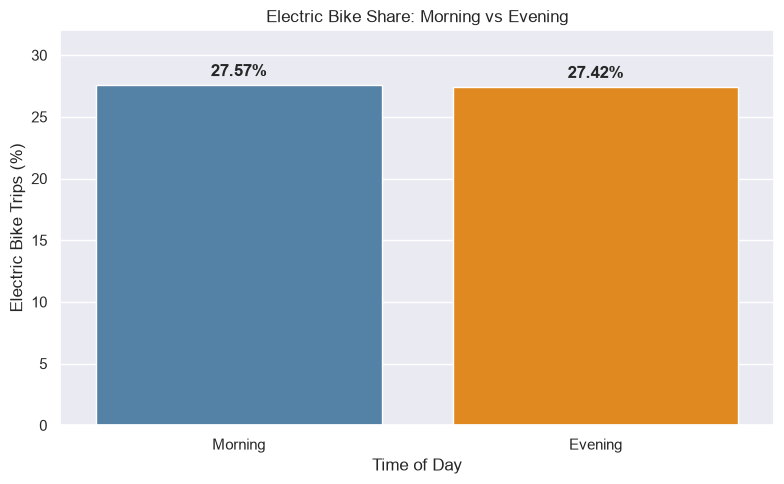

In [1134]:
sns.set_theme(style="darkgrid")

share_plot = electric_share.loc[["Morning", "Evening"]]

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=share_plot.index,
    y=share_plot["electric_share"],
    hue=share_plot.index,
    palette=["steelblue", "darkorange"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4, fontweight="bold")

plt.xlabel("Time of Day")
plt.ylabel("Electric Bike Trips (%)")
plt.title("Electric Bike Share: Morning vs Evening")
plt.ylim(0, 32)
plt.tight_layout()
plt.savefig("Images/hypothesis_17_electric_share.png")
plt.show()

###  Interpretation

The results do not support the hypothesis that the share of electric bike trips is higher in the evening than in the morning.

Electric bikes accounted for 27.57% of morning trips (574 out of 2,082 trips) and 27.42% of evening trips (575 out of 2,097 trips). The difference was only 0.15 percentage points, with the morning share being slightly higher.

The total number of trips and the number of electric bike trips were very similar in both periods. This suggests that the proportion of electric bike usage remains almost unchanged between morning and evening.

**Conclusion:** The hypothesis is not supported by the observed data. The share of electric bike trips is nearly identical in the morning and evening, with no meaningful difference apparent in these descriptive statistics.

## Hypothesis 18: Longer Trips Receive Lower User Ratings

### 1. Hypothesis
Longer trips tend to receive lower user ratings than shorter trips.

### 2. Metrics and Comparison Groups
- **Primary metric:** Average user rating.
- **Explanatory variable:** Trip duration in minutes.
- **Unit of observation:** One trip with a valid duration and rating.
- **Relevant columns:** `duration_min`, `rating`.

### 3. Data Aggregation
We will examine the relationship between trip duration and rating using records with valid values for both variables. We will calculate the correlation coefficient to measure the direction and strength of the relationship.

### 4. Visualization
A scatter plot will show trip duration against user rating. A trend line will help us identify whether ratings generally decrease as trip duration increases.


In [1135]:
# Check the relationship between trip duration and rating
duration_rating = df[["duration_min", "rating"]].dropna()

print("Valid trips:", len(duration_rating))
print("Correlation:", round(
    duration_rating["duration_min"].corr(duration_rating["rating"]), 3
))

Valid trips: 5934
Correlation: -0.029


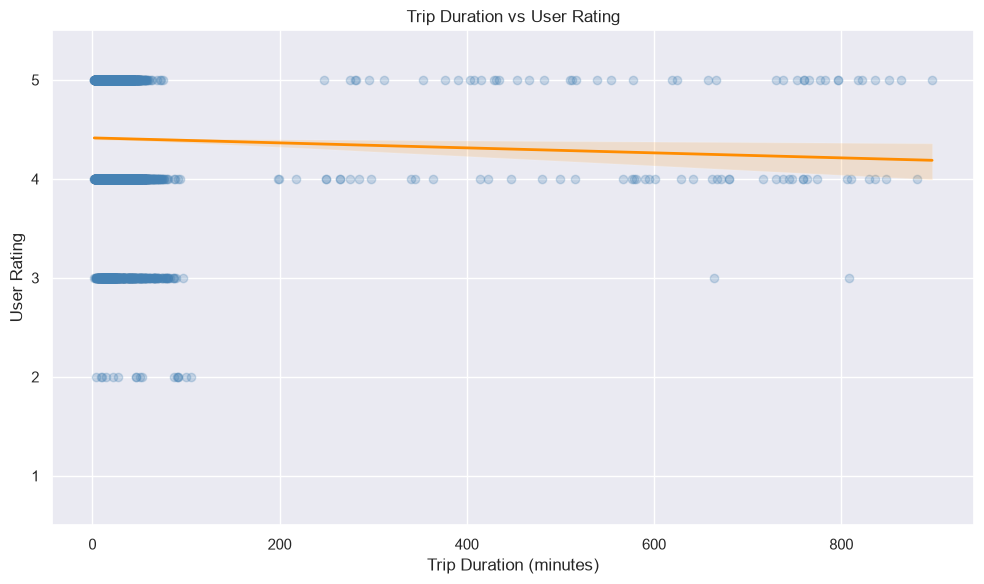

In [1136]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(10, 6))

sns.regplot(
    data=duration_rating,
    x="duration_min",
    y="rating",
    scatter_kws={"alpha": 0.25, "color": "steelblue"},
    line_kws={"color": "darkorange", "linewidth": 2}
)

plt.xlabel("Trip Duration (minutes)")
plt.ylabel("User Rating")
plt.title("Trip Duration vs User Rating")
plt.ylim(0.5, 5.5)
plt.tight_layout()
plt.savefig("Images/hypothesis_18_duration_vs_rating.png")
plt.show()

###  Interpretation

The results do not support the hypothesis that longer trips tend to receive lower user ratings.

The correlation coefficient was -0.029, based on 5,934 trips with valid duration and rating values. This indicates an almost negligible negative linear relationship.

The scatter plot confirms this result. The trend line slopes down only slightly, and trips of different durations received a wide range of ratings. Even some very long trips received ratings of 4 or 5.

These findings suggest that trip duration alone has little linear association with user ratings in this dataset. Other factors may influence user satisfaction, but this analysis does not identify them.

**Conclusion:** The hypothesis is not supported. There is almost no linear relationship between trip duration and user rating, and longer trips do not consistently receive lower ratings.

## Additional Hypothesis 19: Bike Type Preference Differs Between Weekdays and Weekends

### 1. Hypothesis
The proportion of electric and standard bike trips differs between weekdays and weekends.

### 2. Metrics and Comparison Groups
- **Primary metric:** Percentage of trips by bike type.
- **Comparison groups:** Weekdays and weekends.
- **Unit of observation:** One trip.
- **Relevant columns:** `is_weekend`, `bike_type`, `trip_id`.

### 3. Data Aggregation
We will group trips by day type and bike type, count the number of trips in each group, and calculate the percentage of each bike type within weekdays and weekends separately.

### 4. Visualization
A grouped bar chart will compare the percentage of electric and standard bike trips on weekdays and weekends.



In [1137]:
# Compare bike type preference on weekdays and weekends
bike_day_counts = (
    df.groupby(["is_weekend", "bike_type"])
    .size()
    .unstack(fill_value=0)
)

bike_day_counts.index = ["Weekday", "Weekend"]

bike_day_share = (
    bike_day_counts
    .div(bike_day_counts.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

print("Trip counts:")
display(bike_day_counts)

print("Bike type share (%):")
display(bike_day_share)

Trip counts:


bike_type,Electric,Standard
Weekday,1423,3702
Weekend,602,1473


Bike type share (%):


bike_type,Electric,Standard
Weekday,27.77,72.23
Weekend,29.01,70.99


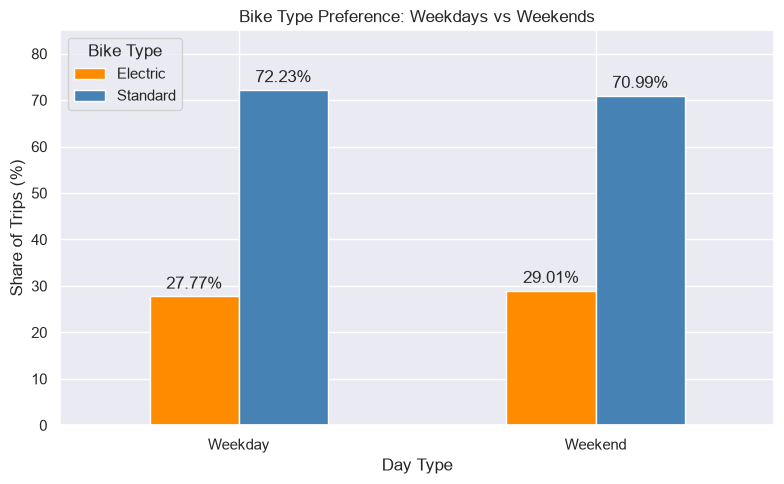

In [1138]:
plt.figure(figsize=(8, 5))

ax = bike_day_share.plot(
    kind="bar",
    color=["darkorange", "steelblue"],
    ax=plt.gca()
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xlabel("Day Type")
plt.ylabel("Share of Trips (%)")
plt.title("Bike Type Preference: Weekdays vs Weekends")
plt.xticks(rotation=0)
plt.legend(title="Bike Type")
plt.ylim(0, 85)
plt.tight_layout()
plt.savefig("Images/hypothesis_19_bike_type_by_day.png")
plt.show()

###  Interpretation

The results show that bike type preference is very similar on weekdays and weekends.

Electric bikes accounted for 27.77% of weekday trips and 29.01% of weekend trips. Standard bikes accounted for 72.23% of weekday trips and 70.99% of weekend trips.

The share of electric bike trips was 1.24 percentage points higher on weekends. However, standard bikes remained the most frequently used type in both groups.

**Conclusion:** The results suggest a small difference in bike type preference between weekdays and weekends, but the overall distribution remains similar. Standard bikes are more popular regardless of day type. 

## Additional Hypothesis 20: Longer Distances Are Associated with Longer Trip Durations

### 1. Hypothesis
Trips with longer distances tend to have longer durations.

### 2. Metrics and Comparison Groups
- **Primary metrics:** Trip distance in kilometers and trip duration in minutes.
- **Unit of observation:** One trip with valid distance and duration values.
- **Relevant columns:** `distance_km`, `duration_min`.

### 3. Data Aggregation
We will calculate the correlation between trip distance and duration to measure the strength and direction of their relationship.

### 4. Visualization
A scatter plot with a trend line will show the relationship between trip distance and trip duration.



In [1139]:
# Check the relationship between distance and duration
distance_duration = df[["distance_km", "duration_min"]].dropna()

print("Valid trips:", len(distance_duration))
print("Correlation:", round(
    distance_duration["distance_km"].corr(
        distance_duration["duration_min"]
    ), 3
))

Valid trips: 6785
Correlation: 0.177


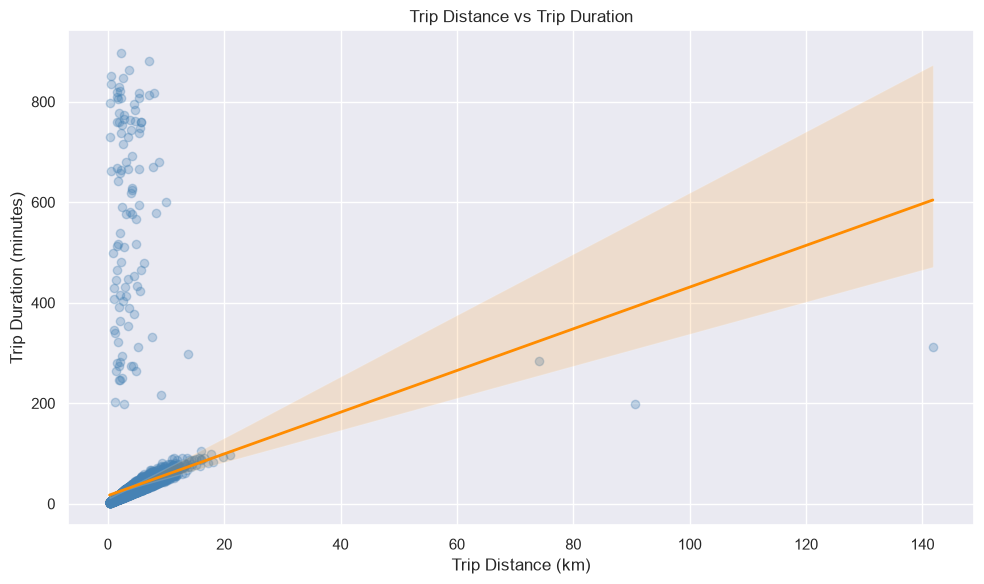

In [1140]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(10, 6))

sns.regplot(
    data=distance_duration,
    x="distance_km",
    y="duration_min",
    scatter_kws={"alpha": 0.3, "color": "steelblue"},
    line_kws={"color": "darkorange", "linewidth": 2}
)

plt.xlabel("Trip Distance (km)")
plt.ylabel("Trip Duration (minutes)")
plt.title("Trip Distance vs Trip Duration")
plt.tight_layout()
plt.savefig("Images/hypothesis_20_distance_vs_duration.png")
plt.show()

###  Interpretation

The results show a weak positive correlation between trip distance and trip duration (0.177). This suggests that longer-distance trips tend to take more time, but the relationship is not strong.

The scatter plot reveals several unusual observations. Some trips lasted more than 800 minutes despite covering relatively short distances. One possible explanation is that users forgot to end their rentals, but this cannot be confirmed from the available data. Other trips covered unusually long distances of approximately 70–145 km.

These observations were retained because there was insufficient evidence to classify them as invalid. However, they may affect the correlation and should be considered when interpreting the results.

**Conclusion:** The hypothesis is partially supported. Trip distance and duration have a weak positive linear relationship, but distance alone does not reliably explain trip duration.

## Heatmap: Number of Trips by Weekday and Hour

### 1. Objective
The objective is to visualize the distribution of bike trips across weekdays and hours of the day. The heatmap will help identify periods of high and low demand.

### 2. Metrics and Variables
- **Primary metric:** Number of trips.
- **Grouping variables:** Day of the week and hour of the day.
- **Relevant columns:** `weekday`, `hour`, `trip_id`.

### 3. Data Aggregation
We will group trips by weekday and hour and calculate the total number of trips for each combination.

### 4. Visualization
A heatmap will display weekdays on the vertical axis and hours on the horizontal axis. Color intensity will represent the number of trips, making demand patterns easier to identify.

### 5. Expected Insights
The heatmap will help identify peak hours, quieter periods, and differences in demand across weekdays. These patterns may indicate periods when bike availability and fleet distribution require additional attention.

In [1141]:
trips_heatmap = df.pivot_table(
    index="weekday",
    columns="hour",
    values="trip_id",
    aggfunc="count",
    fill_value=0
)

trips_heatmap

hour,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,
Friday,15,38,50,73,68,43,41,55,66,58,70,56,81,77,95,56,51,21
Monday,18,37,66,70,63,50,43,54,64,59,59,63,66,108,88,75,48,19
Saturday,15,35,56,73,73,43,34,52,67,75,55,57,70,83,97,88,59,18
Sunday,17,32,71,76,59,47,33,46,63,78,59,63,71,72,75,75,62,26
Thursday,16,28,63,73,72,43,32,49,58,56,53,54,61,93,76,78,55,22
Tuesday,15,30,63,74,68,59,33,58,64,69,76,58,69,77,77,79,54,19
Wednesday,14,30,56,76,72,42,42,51,70,57,58,53,76,95,86,81,51,27


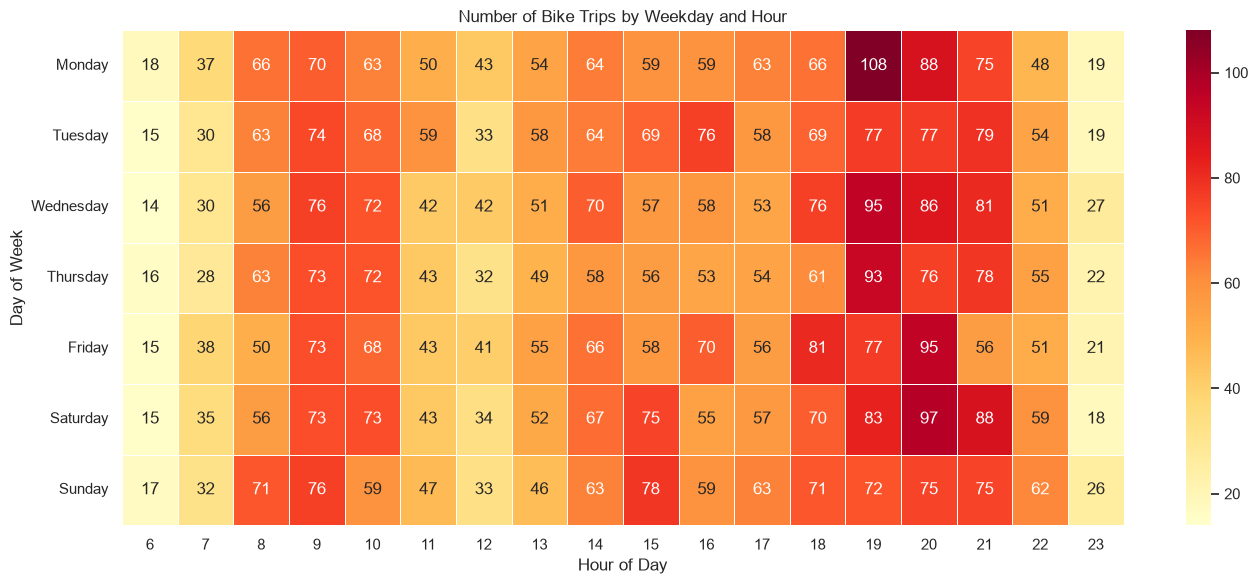

In [1142]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

trips_heatmap = trips_heatmap.reindex(weekday_order)

sns.set_theme(style="darkgrid")

plt.figure(figsize=(14, 6))

sns.heatmap(
    trips_heatmap,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Number of Bike Trips by Weekday and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.savefig("Images/heatmap_weekday_hour.png")
plt.show()

### Interpretation

The heatmap reveals clear differences in bike trip demand across hours and days of the week.

- **Evening demand:** The period between 19:00 and 21:00 shows consistently high activity. Monday has the highest hourly count, with 108 trips at 19:00.
- **Morning demand:** Trip activity is also relatively high between 08:00 and 10:00, particularly on weekdays.
- **Low-demand periods:** The lowest trip counts generally occur early in the morning, especially at 06:00–07:00, and late at night around 23:00.
- **Weekend patterns:** Saturday and Sunday also show substantial activity throughout the day, although their hourly patterns differ from those observed on weekdays.

**Conclusion:** Bike demand varies by both weekday and hour, with prominent morning and evening activity. These patterns can help the business plan bike availability and maintenance schedules. However, the heatmap shows trip counts rather than the causes of demand.

## Top 5 Most Popular Bike Routes

### 1. Objective
The objective is to identify the five most popular routes between bike stations based on the number of trips.

### 2. Metrics and Variables
- **Primary metric:** Number of trips per route.
- **Grouping variables:** Start station and end station.
- **Relevant columns:** `start_station`, `end_station`, `trip_id`.

### 3. Data Aggregation
We will group trips by their starting and ending stations and count the number of trips for each route. Records with missing station names will be excluded from this analysis.

### 4. Visualization
A bar chart will display the five most popular routes, ranked by the number of trips.

### 5. Expected Insights
The analysis will identify the most frequently used station-to-station routes and help reveal common travel patterns within the bike-sharing system.

In [1143]:
route_counts = (
    df.dropna(subset=["start_station", "end_station"])
    .query("start_station != end_station")
    .groupby(["start_station", "end_station"])["trip_id"]
    .count()
    .reset_index(name="trips")
    .sort_values("trips", ascending=False)
)

top_routes = (
    route_counts
    .drop_duplicates(subset="start_station")
    .head(5)
    .set_index(["start_station", "end_station"])["trips"]
)

top_routes


start_station    end_station    
Cascade          Opera              112
Republic Square  Cascade            110
University       Republic Square    101
Opera            Komitas Market      93
Arabkir Park     Komitas Market      86
Name: trips, dtype: int64

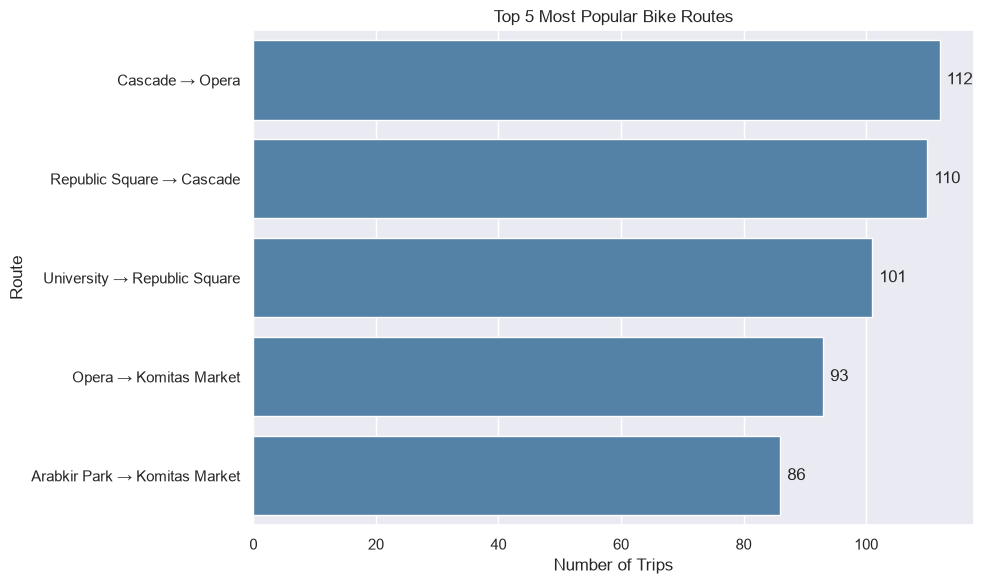

In [1144]:
sns.set_theme(style="darkgrid")

plt.figure(figsize=(10, 6))

route_labels = [
    f"{start} → {end}"
    for start, end in top_routes.index
]

ax = sns.barplot(
    x=top_routes.values,
    y=route_labels,
    color="steelblue"
)

ax.bar_label(ax.containers[0], padding=5)

plt.title("Top 5 Most Popular Bike Routes")
plt.xlabel("Number of Trips")
plt.ylabel("Route")
plt.tight_layout()
plt.savefig("Images/top_5_bike_routes.png")
plt.show()

### Interpretation

The analysis identified the five most popular routes between different starting and ending stations, with a restriction that each route has a unique starting station.

- **Cascade → Opera** is the most popular route, with 112 trips.
- **Republic Square → Cascade** ranks second, with 110 trips.
- **University → Republic Square** ranks third, with 101 trips.
- **Opera → Komitas Market** accounts for 93 trips.
- **Arabkir Park → Komitas Market** has 86 trips.

The number of trips across these five routes ranges from 86 to 112. Cascade appears as a starting station on the most popular route, while Komitas Market is the destination for two of the five routes.

**Conclusion:** The results reveal several frequently used station-to-station routes. These findings may help identify important connections within the bike-sharing network. However, the analysis was restricted to routes with different starting and ending stations and unique starting stations, so the results do not represent the unrestricted top five routes across all possible station pairs.

## Key Findings

### 1. Bike Demand Varies by Time of Day
The heatmap revealed high trip activity during the morning hours (08:00–10:00) and evening hours (19:00–21:00). Demand varies across weekdays and weekends, indicating that bike availability should be planned according to hourly usage patterns.

### 2. Standard Bikes Are Used More Frequently Than Electric Bikes
Standard bikes accounted for approximately 2.5 times as many trips as electric bikes. However, electric bike trips covered a longer average distance (4.21 km compared with 3.13 km for standard bikes).

### 3. Casual Users Take Longer Trips Than Subscribers
Casual users had a higher average trip duration than subscribers (36.42 minutes versus 26.43 minutes). This difference may reflect different usage patterns, although the specific reasons cannot be determined from the available data.

### 4. Electric Bikes Have a Higher Technical Issue Rate
Technical issues were reported in 5.14% of electric bike trips, compared with 2.40% of standard bike trips. This difference highlights the importance of monitoring electric bike reliability and maintenance needs.

### 5. Trip Counts Differ Across Weather Conditions
Sunny trips accounted for 55.7% of all trips, while rainy trips accounted for 15.6%. This indicates an association between recorded weather conditions and trip distribution, but the results alone do not establish a causal relationship.

## Business Recommendations

Based on the data analysis and hypothesis testing, the following recommendations are proposed to improve the bike-sharing service, increase customer engagement, and support business growth. These proposals should be evaluated by the business team before implementation. Their effectiveness and financial impact would need to be measured after testing.

### 1. Promote Electric Bike Adoption

Encourage users to try electric bikes by offering a free trial ride after several trips on a standard bike. For example, the trial could be limited to a distance of 10 km.

Electric bikes had a higher average trip distance than standard bikes (4.21 km compared with 3.13 km), while standard bikes were used approximately 2.5 times more frequently. A trial program could help users discover the benefits of electric bikes and increase their adoption.

### 2. Introduce Discounts for Longer Electric Bike Trips

Consider offering discounts on electric bike trips lasting longer than one hour. Weekend promotions during selected peak periods could also be tested.

These offers could encourage users to choose electric bikes and take longer trips. However, the company should account for the higher observed technical issue rate for electric bikes and evaluate whether additional usage would be financially beneficial.

### 3. Implement a Trip-End Reminder

Introduce an in-app notification when a bicycle has remained stationary for more than 10 minutes. The notification could ask the user whether they have finished their trip and remind them to end the rental if necessary.

The dataset contains unusually long trips with relatively short distances. One possible explanation is that some users forget to end their rentals, although this cannot be confirmed from the available data.

The reminder should not automatically end a trip, since users may stop temporarily during a ride. This feature could help reduce accidental rental extensions and improve bicycle availability.

### 4. Improve Age Verification and Data Quality

Improve age validation during registration by requiring users to enter their age and checking that the value is reasonable. The company could also establish a minimum rental age in accordance with applicable safety requirements and service policies.

Where justified, age verification through an identity document could be considered, subject to applicable privacy and data-protection requirements.

The dataset contained suspicious age values, including ages above 100. Improving age-data quality would support more reliable analysis of customer groups, particularly users aged 60 and above.

### 5. Introduce a Loyalty Program for Subscribers

Create a loyalty program to reward frequent users with an active subscription. For example, every tenth standard-bike trip could be free or discounted, provided that the trip does not exceed 5 km.

This program could encourage more frequent usage, strengthen customer loyalty, and support subscription renewals. The company should compare the cost of the rewards with changes in trip frequency, retention, and subscription revenue.

### 6. Offer Discounts During Bad Weather

Consider temporary discounts during rainy or otherwise unfavorable weather conditions to encourage additional trips.

In the dataset, sunny trips accounted for 55.7% of trips, while rainy trips accounted for 15.6%. These differences provide a reason to test weather-based promotions, but they do not prove that discounts would increase demand or profitability.

A limited pilot could help determine whether the additional trips generate enough revenue to offset the discounts.

### 7. Introduce Dynamic Pricing During Peak Demand

Consider increasing pay-as-you-go prices by a defined percentage during periods of particularly high demand, while keeping subscription pricing unchanged.

This approach could increase revenue during peak periods and make subscriptions more attractive to frequent users. However, price changes should be moderate, transparent, and evaluated carefully to avoid discouraging customers or reducing overall demand.

### 8. Encourage More Users to Subscribe

Develop marketing initiatives that demonstrate the potential benefits of a subscription compared with pay-as-you-go pricing.

Possible actions include showing users how much they could have saved with a subscription, offering subscription promotions after several trips, and highlighting the advantages of subscription pricing during peak-demand periods.

The effectiveness of these initiatives should be evaluated by tracking subscription conversion, customer retention, trip frequency, and overall revenue.

### Final Note

These recommendations are proposals based on the available analysis and should not be treated as proven solutions. The company should prioritize them according to expected business value, implementation costs, operational feasibility, and customer impact. Pilot programs and performance monitoring can help determine which initiatives should be implemented, modified, or discontinued.

## Import Files

In [1145]:
from pathlib import Path

output = Path("output")
output.mkdir(exist_ok=True)


df.to_csv(output / "bike_trips_cleaned.csv", index=False)

df.to_json(
    output / "bike_trips_cleaned.json",
    orient="records",
    indent=2,
    force_ascii=False,
    date_format="iso"
)

df.to_excel(
    output / "bike_trips_cleaned.xlsx",
    index=False
)
